Load all modules

In [1]:
import importlib.util
import sys
import numpy as np
import matplotlib.pyplot as plt


file_path = r"C:\Users\wagne\OneDrive\Dokumente\Universität\Master_Elektrotechnik\3.Semester\Forschungspraktikum\Code\K_PF_time_homogeneous_Markovian_RDS\Packages\EDMD.py"

spec = importlib.util.spec_from_file_location("edmd", file_path)
module = importlib.util.module_from_spec(spec)
sys.modules["edmd"] = module
spec.loader.exec_module(module)

file_path = r"C:\Users\wagne\OneDrive\Dokumente\Universität\Master_Elektrotechnik\3.Semester\Forschungspraktikum\Code\K_PF_time_homogeneous_Markovian_RDS\Packages\ULAM.py"

spec = importlib.util.spec_from_file_location("ulam", file_path)
module = importlib.util.module_from_spec(spec)
sys.modules["ulam"] = module
spec.loader.exec_module(module)

file_path = r"C:\Users\wagne\OneDrive\Dokumente\Universität\Master_Elektrotechnik\3.Semester\Forschungspraktikum\Code\K_PF_time_homogeneous_Markovian_RDS\Packages\function_dictionary.py"

spec = importlib.util.spec_from_file_location("function_dictionary", file_path)
module = importlib.util.module_from_spec(spec)
sys.modules["function_dictionary"] = module
spec.loader.exec_module(module)

file_path = r"C:\Users\wagne\OneDrive\Dokumente\Universität\Master_Elektrotechnik\3.Semester\Forschungspraktikum\Code\K_PF_time_homogeneous_Markovian_RDS\Problems\Orenstein_Uhlenbeck.py"

spec = importlib.util.spec_from_file_location("Orenstein_Uhlenbeck", file_path)
module = importlib.util.module_from_spec(spec)
sys.modules["Orenstein_Uhlenbeck"] = module
spec.loader.exec_module(module)

# Orenstein--Uhlenbeck Problem

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import math

## Setup

In [3]:
alpha = 4
D = 0.25

h= 10**(-3)

Nt = 1000 # timesteps

Nx = 1000
x = np.linspace(-2, 2, Nx)

OU = sys.modules["Orenstein_Uhlenbeck"].Ornstein_Uhlenbeck(alpha=alpha, D=D, h=h)

## Eigenvalues

### Visualize Eigenvalues

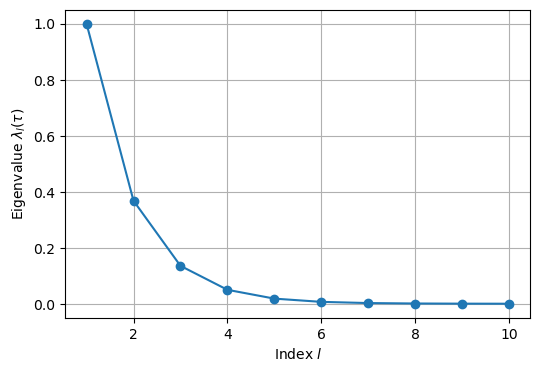

In [4]:
tau = 1.0
# First 10 eigenvalues
l_vals = np.arange(1, 11)
eig_vals = OU.eig_val(l_vals, tau)

plt.figure(figsize=(6, 4))
plt.plot(l_vals, eig_vals, 'o-')
plt.xlabel(r"Index $l$")
plt.ylabel(r"Eigenvalue $\lambda_l(\tau)$")
#plt.title(f"First 10 OU Eigenvalues ($\\tau={tau}$)")
plt.grid(True)
plt.show()

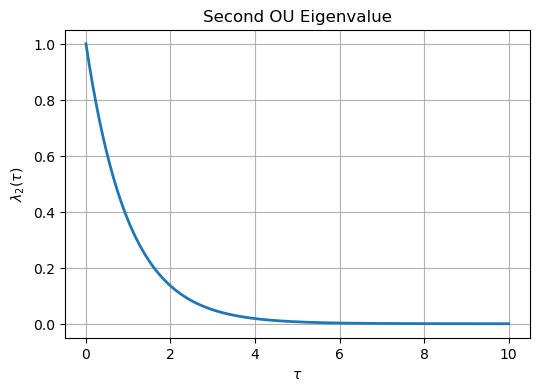

In [5]:
tau = np.linspace(0, 10, 500)

plt.figure(figsize=(6,4))
plt.plot(tau, OU.eig_val(2, tau), lw=2)
plt.xlabel(r'$\tau$')
plt.ylabel(r'$\lambda_2(\tau)$')
plt.title('Second OU Eigenvalue')
plt.grid(True)
plt.show()

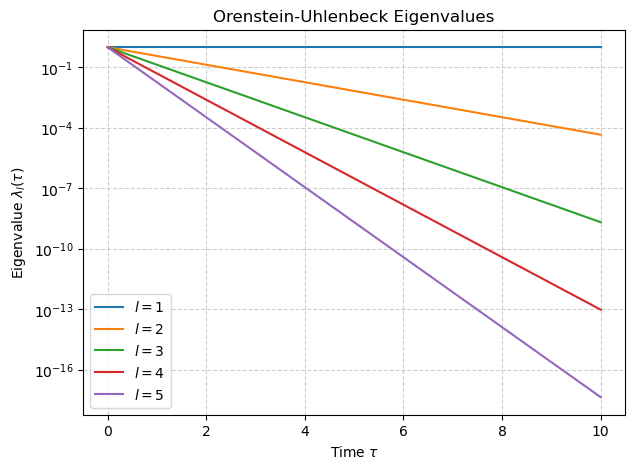

In [6]:
tau = np.linspace(0, 10, 500)

plt.figure(figsize=(7, 5))

for l in range(1, 6):  # first 5 eigenvalues
    plt.semilogy(
        tau,
        OU.eig_val(l, tau),
        label=fr"$l={l}$"
    )

plt.xlabel(r"Time $\tau$")
plt.ylabel(r"Eigenvalue $\lambda_l(\tau)$")
plt.title("Orenstein-Uhlenbeck Eigenvalues")
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.legend()
plt.show()

## Eigenfunctions

### Visualize Eigenfunctions

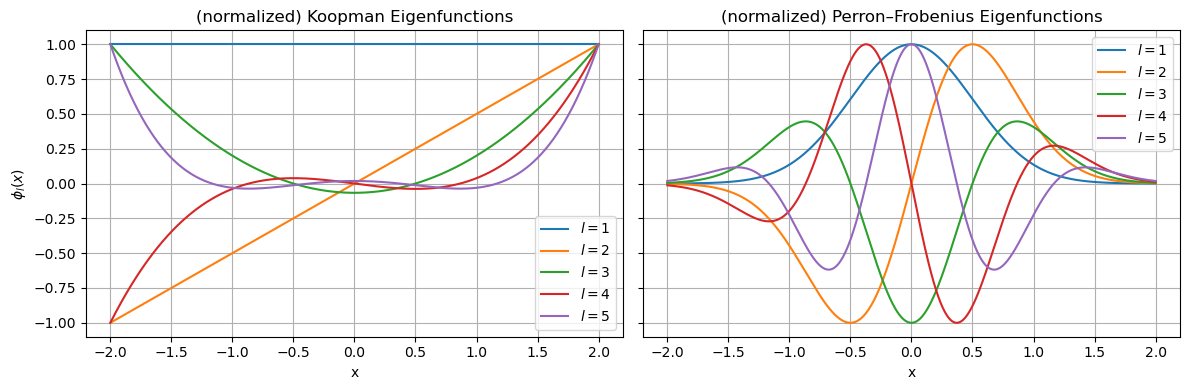

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)

# Left: Koopman
for l in range(1, 6):
    phi = OU.eig_func_KOP(l, x)
    phi = phi / np.max(np.abs(phi))  # Normalize for better visualization
    axes[0].plot(
        x,
        phi,
        label=fr"$l={l}$"
    )

axes[0].set_title("(normalized) Koopman Eigenfunctions")
axes[0].set_xlabel("x")
axes[0].set_ylabel(r"$\phi_l(x)$")
axes[0].grid(True)
axes[0].legend()

# Right: Perron–Frobenius
for l in range(1, 6):
    phi = OU.eig_func_POP(l, x)
    phi = phi / np.max(np.abs(phi))  # Normalize for better visualization
    axes[1].plot(
        x,
        phi,
        label=fr"$l={l}$"
    )

axes[1].set_title("(normalized) Perron–Frobenius Eigenfunctions")
axes[1].set_xlabel("x")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

## Orenstein Uhlenbeck process

## Viusalize Orenstein-Uhlenbeck process

In [8]:
X = np.random.uniform(-2, 2, size=10000)
Y = OU.simulate(
    x0=X,
    N = Nt,
    show_progress=True
)

Simulating: 100%|██████████| 1000/1000 [00:00<00:00, 2673.71it/s]


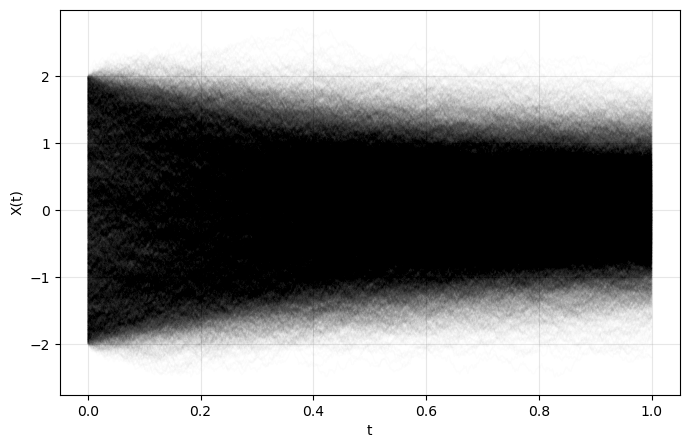

In [9]:
# time axis
t = np.arange(Y.shape[0]) * h

# plot trajectories
plt.figure(figsize=(8, 5))
plt.plot(t, Y, lw=1, alpha=0.01, color='black')
plt.xlabel("t")
plt.ylabel("X(t)")
#plt.title("Ornstein-Uhlenbeck trajectories")
plt.grid(alpha=0.3)
plt.show()

## Numerical Methods

### ULAM Method

In [10]:
# ----------------------------
# Domain
# ----------------------------
xmin, xmax = -2, 2

# Number of boxes per dimension
#Nx = 10000
Nx = 100

# Samples per box
#n_per_box = 1000
n_per_box = 1000

Domain = [[xmin, xmax]]

Nt = 1000

In [11]:
ulam = sys.modules["ulam"].Ulam(Domain, N=[Nx], n_per_box=n_per_box)
X = ulam.sample_points()
Y = OU.simulate_fast(
    x0=X,
    N=Nt,
    show_progress=True
)

Simulating fast: 100%|██████████| 1000/1000 [00:03<00:00, 281.28it/s]


In [12]:
P = ulam.setup(X=X,Y=Y)

Building Ulam matrix (fast): 100%|██████████| 100000/100000 [00:06<00:00, 15748.55it/s]


### EDMD Method

In [13]:
M = sys.modules["function_dictionary"].Monomials(10, TotalDegree=False, dim=1)
H = sys.modules["function_dictionary"].probabilistic_Hermite_polynomials(10, dim=1)
L = sys.modules["function_dictionary"].Legendre_polynomials(10, dim=1)
F = sys.modules["function_dictionary"].Fourier_functions(10, dim=1)


In [14]:

edmd_M = sys.modules["edmd"].EDMD()
edmd_H = sys.modules["edmd"].EDMD()
edmd_L = sys.modules["edmd"].EDMD()
edmd_F = sys.modules["edmd"].EDMD()


In [15]:
edmd_M.setup(X, Y, M)
edmd_H.setup(X, Y, H)
edmd_L.setup(X, Y, L)
edmd_F.setup(X, Y, F)

Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 100000/100000 [00:07<00:00, 12506.56it/s]


G condition number: 130051294.15122199
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
1.0488670083815809e-05
Computing eigenvalues, eigenvectors and eigenfunctions...
Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 100000/100000 [00:10<00:00, 9131.38it/s]


G condition number: 5162512560422.016
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
0.22469699184516428
Computing eigenvalues, eigenvectors and eigenfunctions...
Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 100000/100000 [00:11<00:00, 8583.37it/s]


G condition number: 4771426789.431786
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
1.118979430851315e-06
Computing eigenvalues, eigenvectors and eigenfunctions...
Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 100000/100000 [00:16<00:00, 6098.66it/s]

G condition number: 45275.01293564706
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
9.632641483454575e-09
Computing eigenvalues, eigenvectors and eigenfunctions...


## Compare 5 Eigenvalues

exact eigenvalues: [1.         0.36787944 0.13533528 0.04978707 0.01831564]
EDMD_M eigenvalues: [1.         0.36847144 0.13616563 0.04649271 0.01642299]
EDMD_H eigenvalues: [1.         0.36847144 0.13616561 0.04649271 0.01642301]
EDMD_L eigenvalues: [1.         0.36847144 0.13616563 0.04649271 0.01642299]
EDMD_F eigenvalues: [1.         0.3685039  0.13600561 0.04704509 0.01598884]
ULAM eigenvalues: [1.         0.36820877 0.13464164 0.04809036 0.02654913]


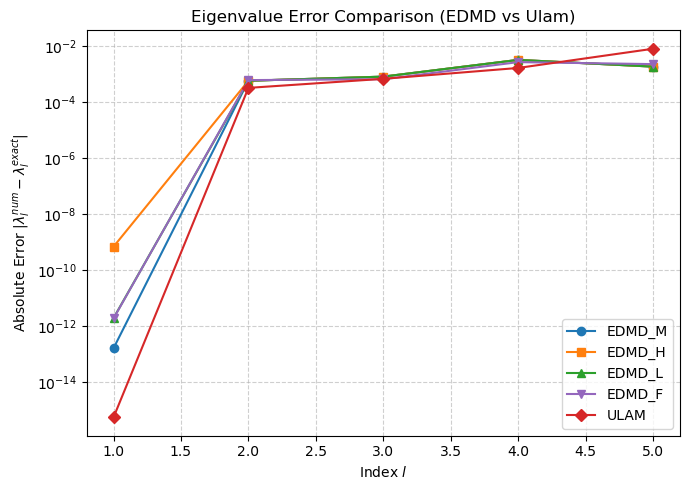

In [16]:
# ---------------------------------------------------
# Models + styling
# ---------------------------------------------------
models = {
    "EDMD_M": edmd_M,
    "EDMD_H": edmd_H,
    "EDMD_L": edmd_L,
    "EDMD_F": edmd_F,
    "ULAM": ulam,
}

markers = {
    "EDMD_M": "o",
    "EDMD_H": "s",
    "EDMD_L": "^",
    "EDMD_F": "v",
    "ULAM": "D"
}

colors = {
    "EDMD_M": "tab:blue",
    "EDMD_H": "tab:orange",
    "EDMD_L": "tab:green",
    "EDMD_F": "tab:purple",
    "ULAM": "tab:red"
}

# ---------------------------------------------------
# Exact eigenvalues
# ---------------------------------------------------
lvals = np.arange(1, 6)
tau = h  # time step (or your effective timestep Nt*h if needed)

lambda_exact = np.array([
    OU.eig_val(l, tau=Nt*h) for l in lvals
])
print(f"exact eigenvalues:", lambda_exact)

# ---------------------------------------------------
# Compute errors
# ---------------------------------------------------
plt.figure(figsize=(7, 5))

for name, model in models.items():
    
    lambda_num = np.array(model.K_dict["eigenvalue"][:5])
    lambda_num = np.real(lambda_num)

    # -----------------------------
    # Error
    # -----------------------------
    abs_error = np.abs(lambda_num - lambda_exact)

    print(f"{name} eigenvalues:", lambda_num)

    plt.semilogy(
        lvals,
        abs_error,
        marker=markers[name],
        color=colors[name],
        linestyle="-",
        linewidth=1.5,
        markersize=6,
        label=name
    )

# ---------------------------------------------------
# Plot formatting
# ---------------------------------------------------
plt.xlabel(r"Index $l$")
plt.ylabel(r"Absolute Error $|\lambda_l^{num} - \lambda_l^{exact}|$")
plt.title("Eigenvalue Error Comparison (EDMD vs Ulam)")
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

## Compare 5 Eigenfunctions

### Perron--Frobenius operator

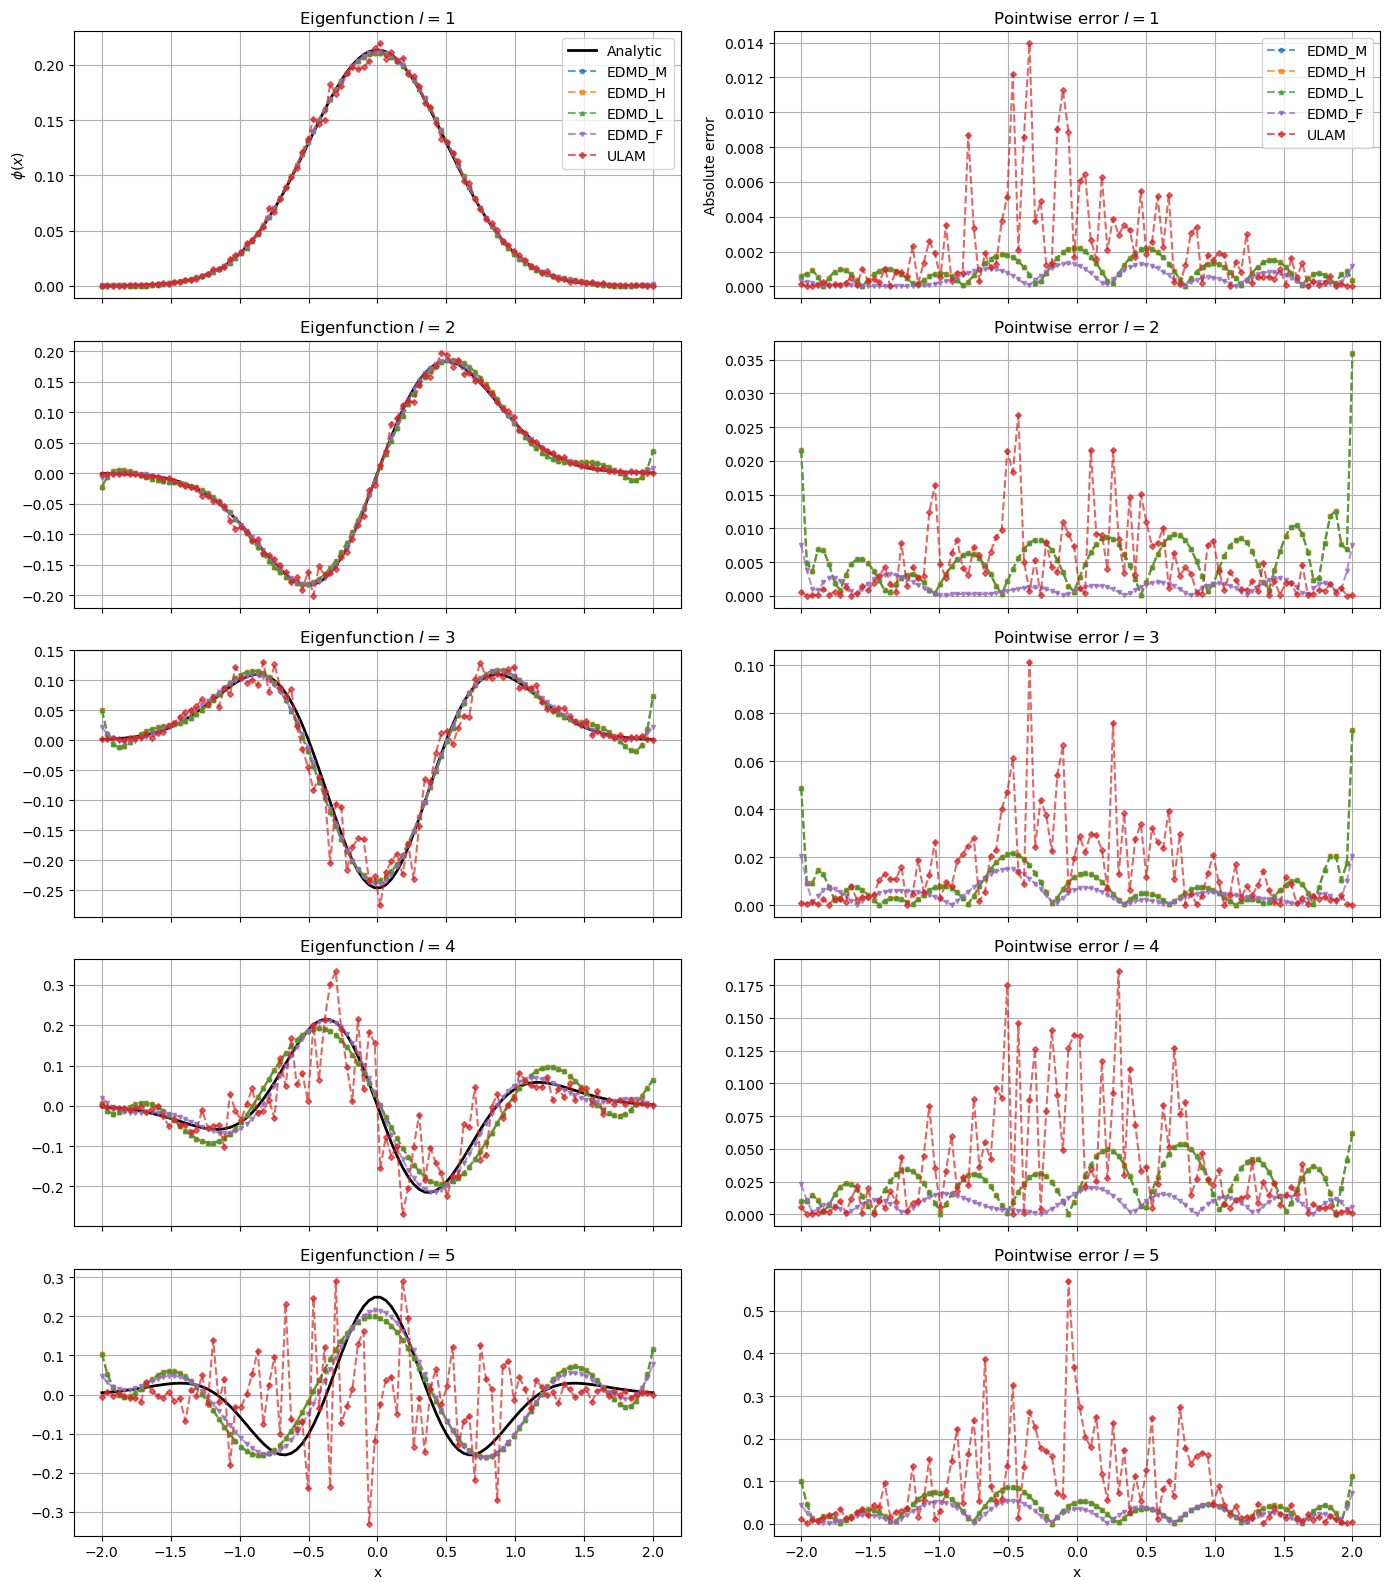

In [17]:
# Store all EDMD models
models = {
    "EDMD_M": edmd_M,
    "EDMD_H": edmd_H,
    "EDMD_L": edmd_L,
    "EDMD_F": edmd_F,
    "ULAM": ulam,
}

markers = {
    "EDMD_M": "o",   # circle
    "EDMD_H": "s",   # square
    "EDMD_L": "^",   # triangle
    "EDMD_F": "v",   # pentagon
    "ULAM": "D"      # diamond (if you enable it)
}

colors = {
    "EDMD_M": "tab:blue",
    "EDMD_H": "tab:orange",
    "EDMD_L": "tab:green",
    "EDMD_F": "tab:purple",
    "ULAM": "tab:red"
}

# Initialize error storage
L2_errors = {name: [] for name in models}
Linf_errors = {name: [] for name in models}

x = np.linspace(xmin, xmax, Nx)

fig, axes = plt.subplots(
    5, 2,
    figsize=(14, 16),
    sharex=True
)

for i in range(5):

    l = i + 1

    # Exact eigenfunction
    phi_exact = OU.eig_func_POP(l, x)
    phi_exact /= np.linalg.norm(phi_exact)

    # Plot analytic reference
    axes[i, 0].plot(x, phi_exact, 'k', lw=2, label="Analytic")

    # Compare each EDMD model
    for name, model in models.items():

        phi_num = np.array([
            model.P_dict["eigenfunction"][i](np.array([xx]))
            for xx in x
        ])

        phi_num = phi_num.real
        phi_num /= np.linalg.norm(phi_num)

        # Sign alignment
        if np.dot(phi_exact, phi_num) < 0:
            phi_num = -phi_num

        abs_error = np.abs(phi_num - phi_exact)

        # Errors
        L2_errors[name].append(np.linalg.norm(phi_num - phi_exact))
        Linf_errors[name].append(np.max(abs_error))

        # Plot numerical eigenfunction
        axes[i, 0].plot(
                        x, phi_num,
                        marker=markers[name],
                        color=colors[name],
                        linestyle="--",
                        markersize=3,
                        alpha=0.7,
                        label=f"{name}"
                    )

        # Plot pointwise error
        axes[i, 1].plot(
                        x, abs_error,
                        marker=markers[name],
                        color=colors[name],
                        linestyle="--",
                        markersize=3,
                        alpha=0.7,
                        label=f"{name}"
                    )

    axes[i, 0].set_title(f"Eigenfunction $l={l}$")
    axes[i, 0].grid(True)

    axes[i, 1].set_title(f"Pointwise error $l={l}$")
    axes[i, 1].grid(True)

    if i == 0:
        axes[i, 0].legend()
        axes[i, 1].legend()

# Shared labels
for ax in axes[-1, :]:
    ax.set_xlabel("x")

axes[0, 0].set_ylabel(r"$\phi(x)$")
axes[0, 1].set_ylabel("Absolute error")

plt.tight_layout()
plt.show()

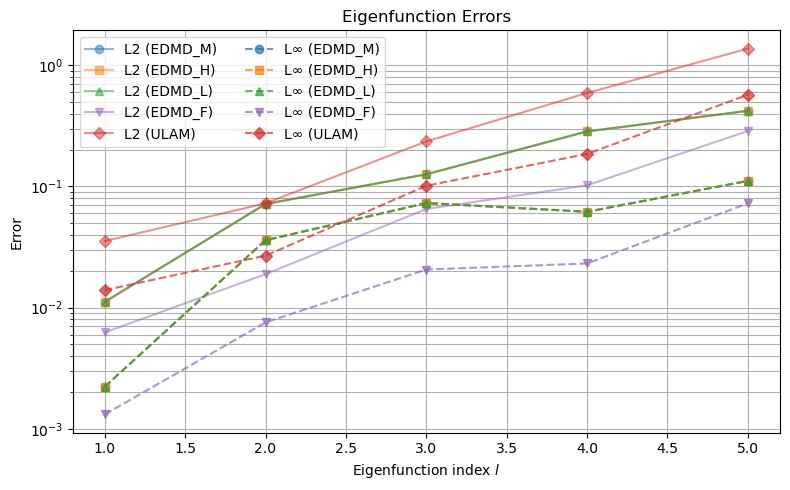

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))

for name in models:

    ax.semilogy(
        range(1, 6),
        L2_errors[name],
        linestyle="-",
        color=colors[name],
        marker=markers[name],
        label=f"L2 ({name})",
        alpha = 0.5
    )

for name in models:
    ax.semilogy(
        range(1, 6),
        Linf_errors[name],
        linestyle="--",
        color=colors[name],
        marker=markers[name],
        label=f"L∞ ({name})",
        alpha = 0.7
    )

ax.set_xlabel("Eigenfunction index $l$")
ax.set_ylabel("Error")
ax.set_title("Eigenfunction Errors")
ax.grid(True, which="both")
ax.legend(ncol=2)

plt.tight_layout()
plt.show()

### Koopman

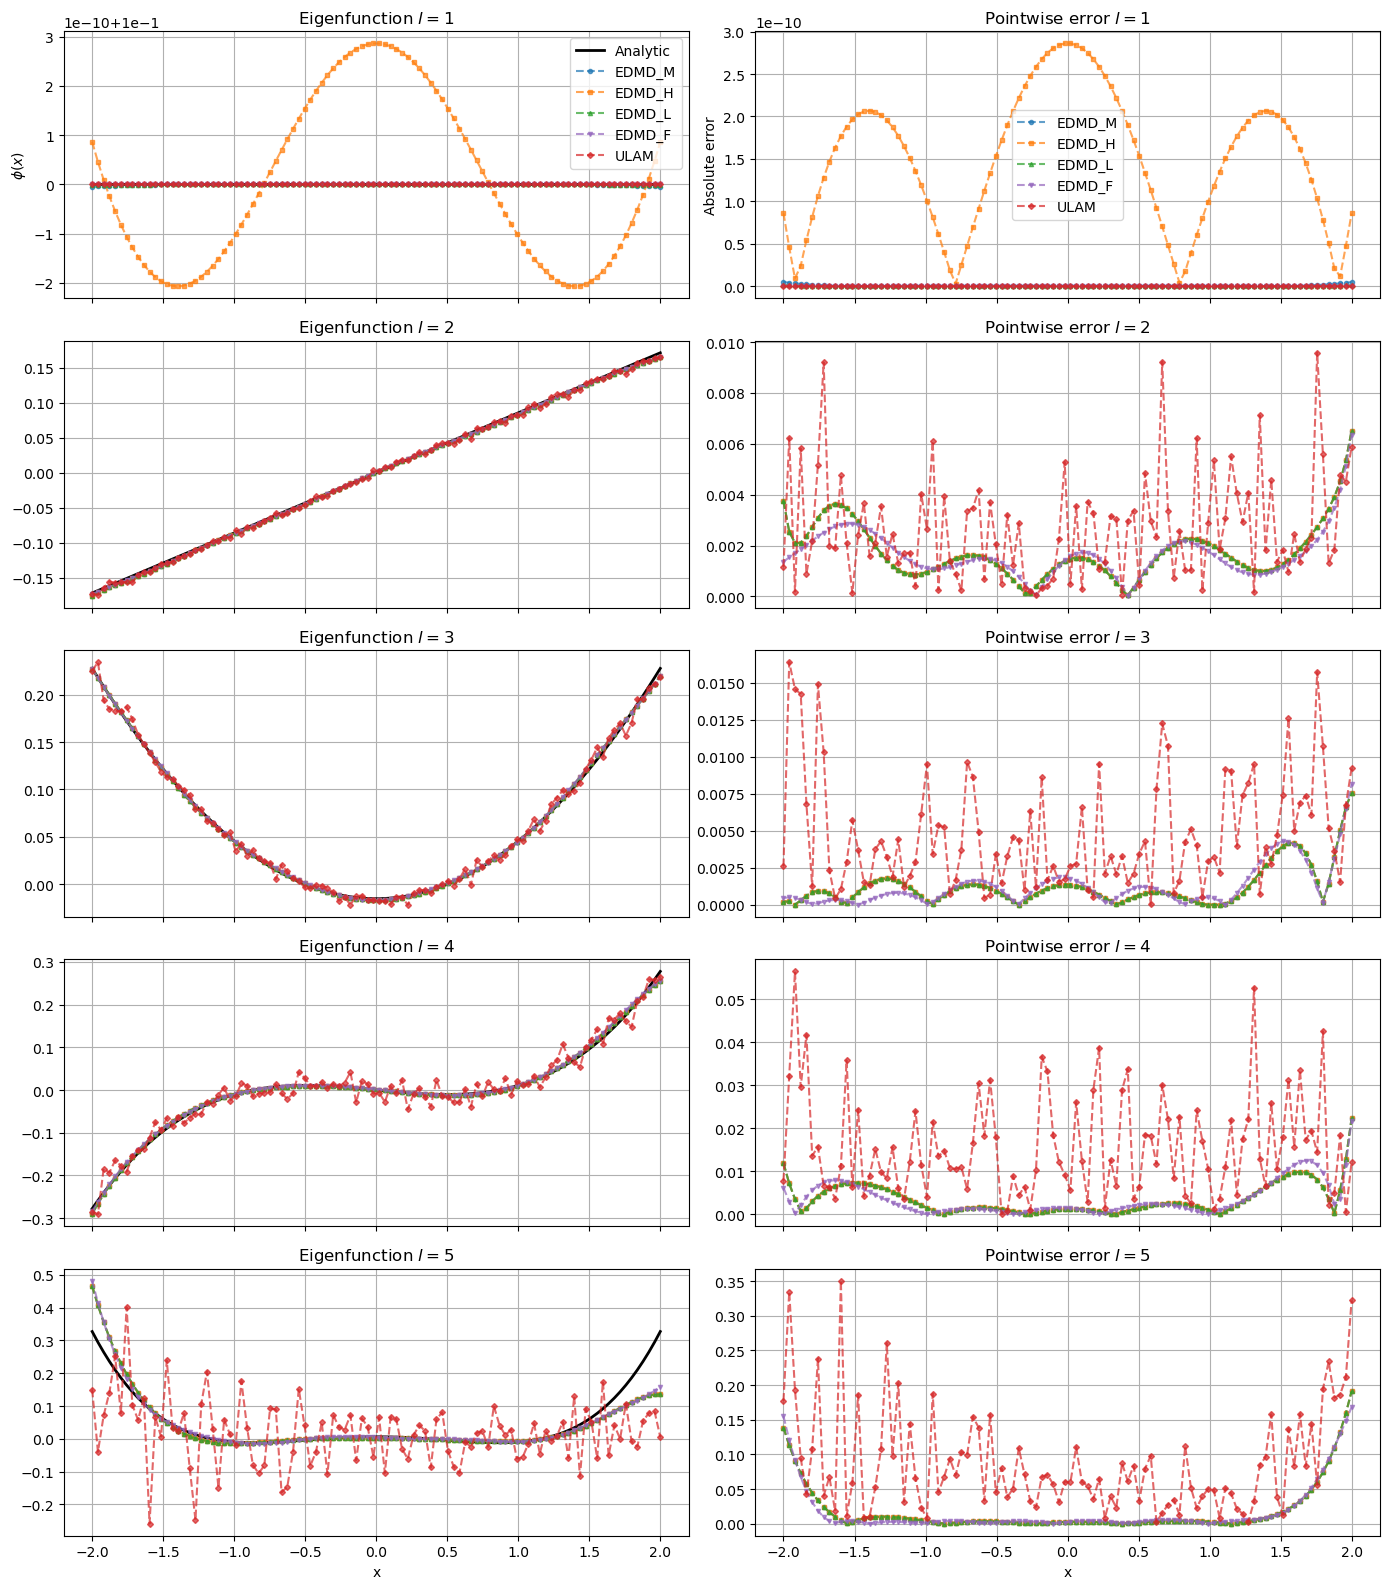

In [19]:
# Store all EDMD models
models = {
    "EDMD_M": edmd_M,
    "EDMD_H": edmd_H,
    "EDMD_L": edmd_L,
    "EDMD_F": edmd_F,
    "ULAM": ulam,
}

markers = {
    "EDMD_M": "o",   # circle
    "EDMD_H": "s",   # square
    "EDMD_L": "^",   # triangle
    "EDMD_F": "v",   # pentagon
    "ULAM": "D"      # diamond (if you enable it)
}

colors = {
    "EDMD_M": "tab:blue",
    "EDMD_H": "tab:orange",
    "EDMD_L": "tab:green",
    "EDMD_F": "tab:purple",
    "ULAM": "tab:red"
}

# Initialize error storage
L2_errors = {name: [] for name in models}
Linf_errors = {name: [] for name in models}

x = np.linspace(xmin, xmax, Nx)

fig, axes = plt.subplots(
    5, 2,
    figsize=(14, 16),
    sharex=True
)

for i in range(5):

    l = i + 1

    # Exact eigenfunction
    phi_exact = OU.eig_func_KOP(l, x)
    phi_exact /= np.linalg.norm(phi_exact)

    # Plot analytic reference
    axes[i, 0].plot(x, phi_exact, 'k', lw=2, label="Analytic")

    # Compare each EDMD model
    for name, model in models.items():

        phi_num = np.array([
            model.K_dict["eigenfunction"][i](np.array([xx]))
            for xx in x
        ])

        phi_num = phi_num.real
        phi_num /= np.linalg.norm(phi_num)

        # Sign alignment
        if np.dot(phi_exact, phi_num) < 0:
            phi_num = -phi_num

        abs_error = np.abs(phi_num - phi_exact)

        # Errors
        L2_errors[name].append(np.linalg.norm(phi_num - phi_exact))
        Linf_errors[name].append(np.max(abs_error))

        # Plot numerical eigenfunction
        axes[i, 0].plot(
                        x, phi_num,
                        marker=markers[name],
                        color=colors[name],
                        linestyle="--",
                        markersize=3,
                        alpha=0.7,
                        label=f"{name}"
                    )

        # Plot pointwise error
        axes[i, 1].plot(
                        x, abs_error,
                        marker=markers[name],
                        color=colors[name],
                        linestyle="--",
                        markersize=3,
                        alpha=0.7,
                        label=f"{name}"
                    )

    axes[i, 0].set_title(f"Eigenfunction $l={l}$")
    axes[i, 0].grid(True)

    axes[i, 1].set_title(f"Pointwise error $l={l}$")
    axes[i, 1].grid(True)

    if i == 0:
        axes[i, 0].legend()
        axes[i, 1].legend()

# Shared labels
for ax in axes[-1, :]:
    ax.set_xlabel("x")

axes[0, 0].set_ylabel(r"$\phi(x)$")
axes[0, 1].set_ylabel("Absolute error")

plt.tight_layout()
plt.show()

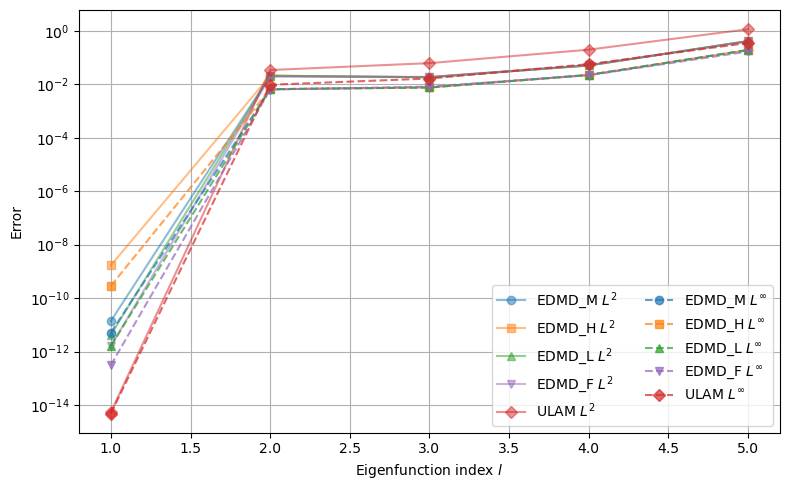

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))

for name in models:

    ax.semilogy(
        range(1, 6),
        L2_errors[name],
        linestyle="-",
        color=colors[name],
        marker=markers[name],
        label=fr"{name} $L^2$",
        alpha = 0.5
    )

for name in models:
    ax.semilogy(
        range(1, 6),
        Linf_errors[name],
        linestyle="--",
        color=colors[name],
        marker=markers[name],
        label=fr"{name} $L^\infty$",
        alpha = 0.7
    )

ax.set_xlabel("Eigenfunction index $l$")
ax.set_ylabel("Error")
#ax.set_title("Eigenfunction Errors")
ax.grid(True, which="both")
ax.legend(ncol=2)

plt.tight_layout()
plt.show()

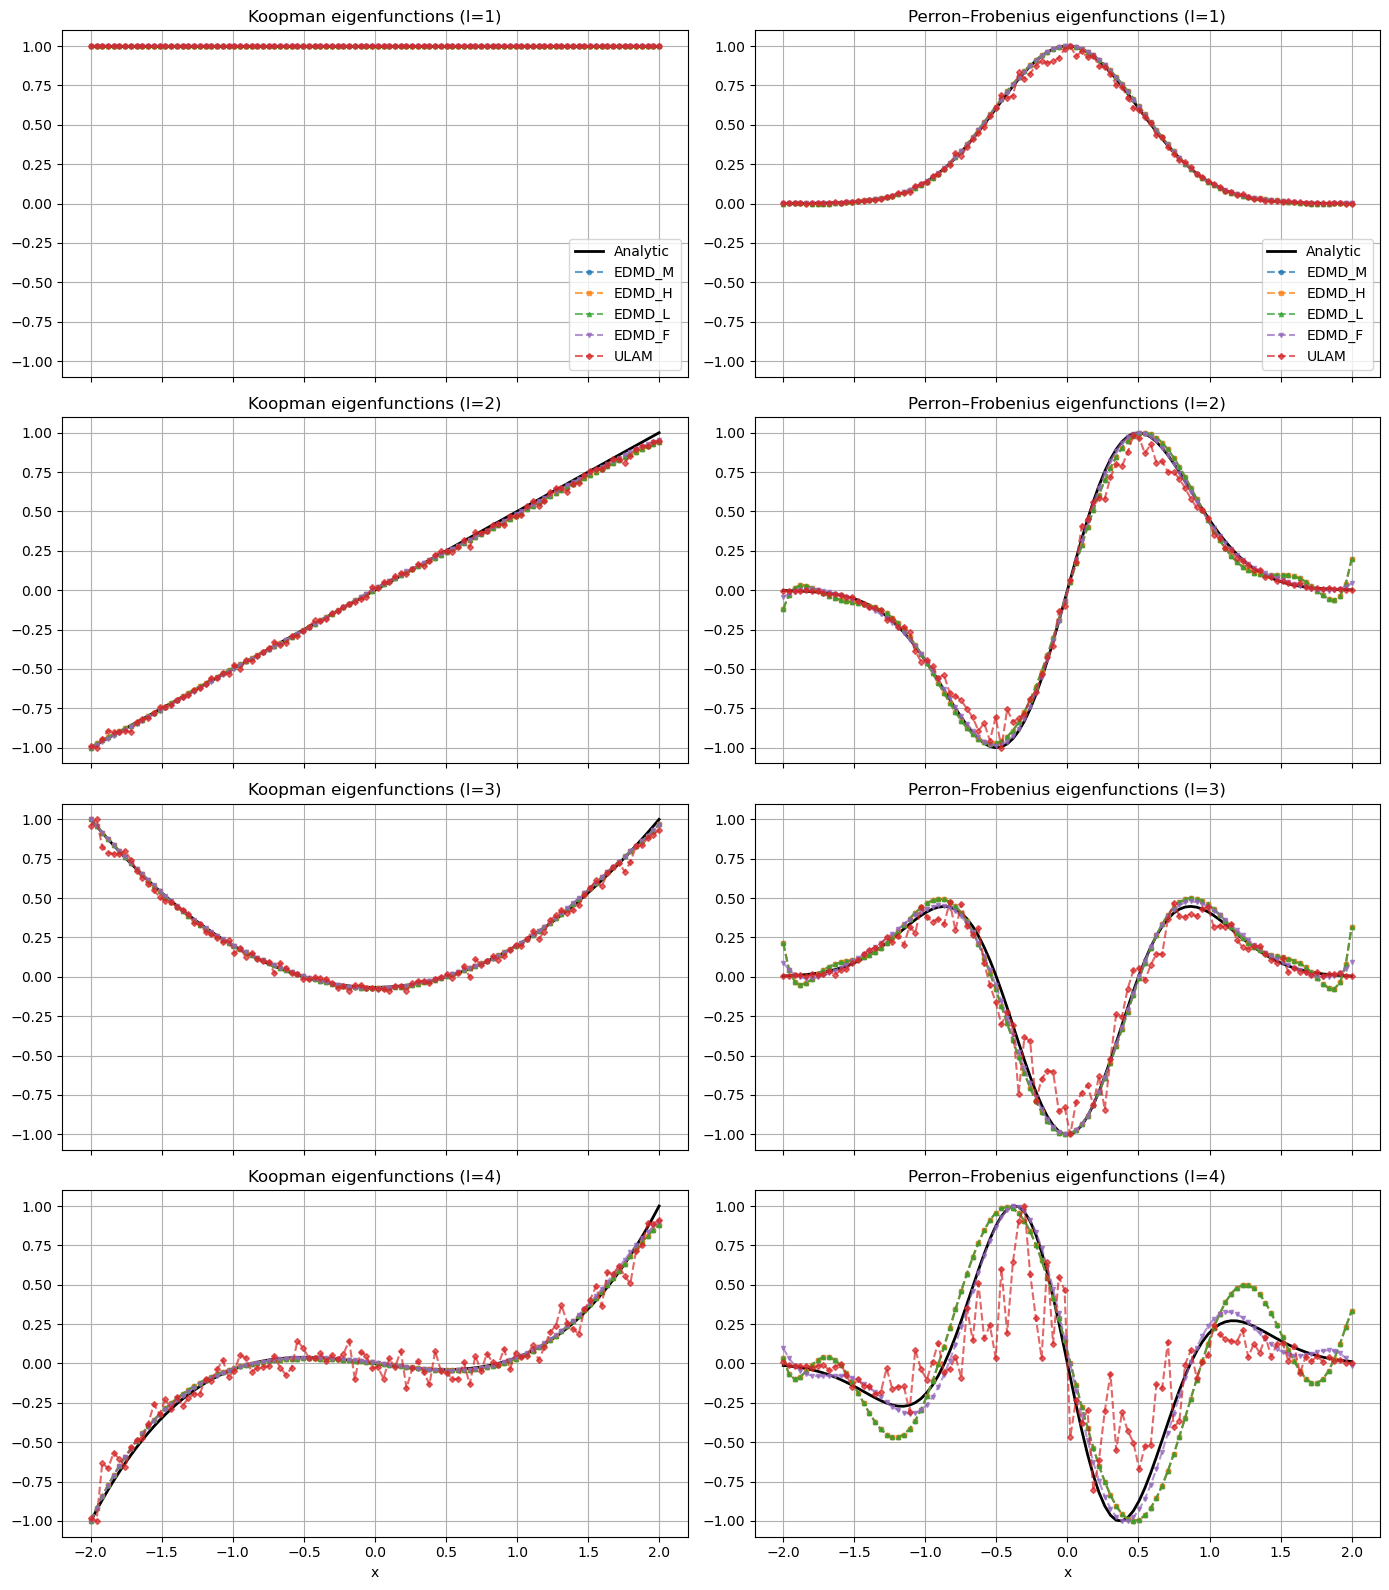

In [21]:
n_plot = 4  # Number of eigenfunctions to plot
fig, axes = plt.subplots(
    n_plot, 2,
    figsize=(14, 16),
    sharex=True
)

for i in range(n_plot):

    l = i + 1

    # Exact eigenfunction
    phi_exact = OU.eig_func_KOP(l, x)
    phi_exact /= (np.max(np.abs(phi_exact))+1e-12)

    # -------------------------
    # LEFT: Koopman (K_dict)
    # -------------------------
    axes[i, 0].plot(x, phi_exact, 'k', lw=2, label="Analytic")

    for name, model in models.items():

        phi_num = np.array([
            model.K_dict["eigenfunction"][i](np.array([xx]))
            for xx in x
        ]).real

        phi_num /= (np.max(np.abs(phi_num))+1e-12)

        # sign alignment
        if np.dot(phi_exact, phi_num) < 0:
            phi_num = -phi_num

        axes[i, 0].plot(
            x, phi_num,
            marker=markers[name],
            color=colors[name],
            linestyle="--",
            markersize=3,
            alpha=0.7,
            label=name
        )

    axes[i, 0].set_title(f"Koopman eigenfunctions (l={l})")
    axes[i, 0].grid(True)
    for ax in axes[:, 0]:
        ax.ticklabel_format(axis='y', style='plain', useOffset=False)
    for ax in axes[:, 1]:
        ax.ticklabel_format(axis='y', style='plain', useOffset=False)
    axes[i, 0].set_ylim([-1.1,1.1])


    # Exact eigenfunction
    phi_exact = OU.eig_func_POP(l, x)
    phi_exact /= (np.max(np.abs(phi_exact))+1e-12)

    axes[i, 1].plot(x, phi_exact, 'k', lw=2, label="Analytic")

    for name, model in models.items():

        phi_num = np.array([
            model.P_dict["eigenfunction"][i](np.array([xx]))
            for xx in x
        ]).real

        phi_num /= (np.max(np.abs(phi_num))+1e-12)

        if np.dot(phi_exact, phi_num) < 0:
            phi_num = -phi_num

        abs_error = np.abs(phi_num - phi_exact)

        axes[i, 1].plot(
            x, phi_num,
            marker=markers[name],
            color=colors[name],
            linestyle="--",
            markersize=3,
            alpha=0.7,
            label=name
        )

    axes[i, 1].set_title(f"Perron–Frobenius eigenfunctions (l={l})")
    axes[i, 1].grid(True)
    axes[i, 1].set_ylim([-1.1,1.1])

    # legends only once
    if i == 0:
        axes[i, 0].legend(loc="lower right")
        axes[i, 1].legend(loc="lower right")

# shared labels
for ax in axes[-1, :]:
    ax.set_xlabel("x")



plt.tight_layout()
plt.show()

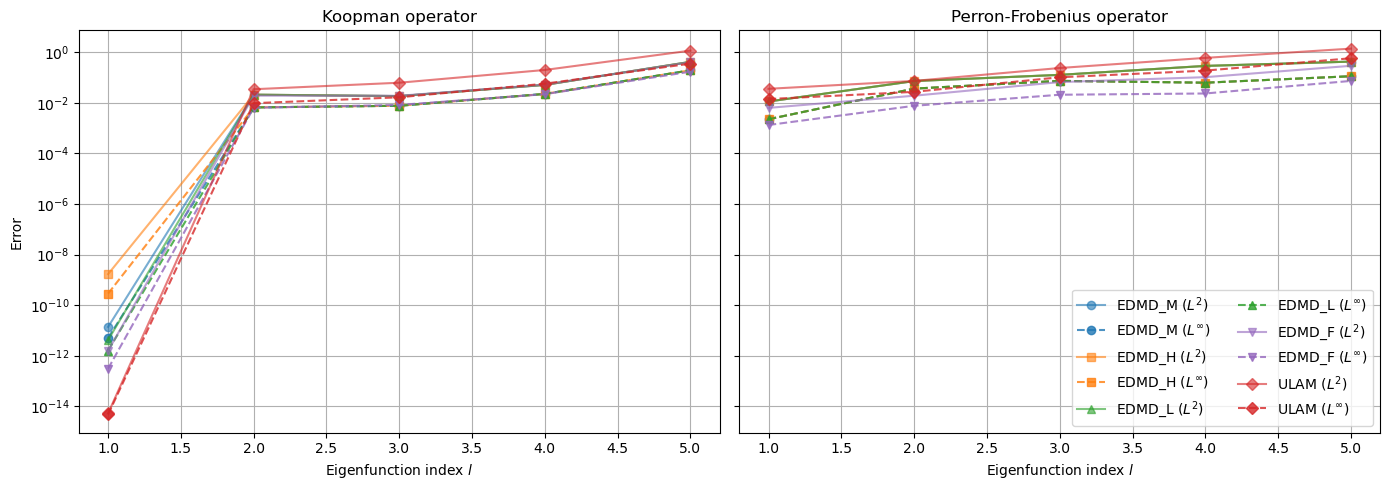

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# ----------------------------
# KOOPMAN ERRORS (K)
# ----------------------------
for name in models:

    K_L2 = []
    K_Linf = []

    for i in range(5):

        l = i + 1

        phi_exact = OU.eig_func_KOP(l, x)
        phi_exact /= np.linalg.norm(phi_exact)

        phi_num = np.array([
            models[name].K_dict["eigenfunction"][i](np.array([xx]))
            for xx in x
        ]).real

        phi_num /= np.linalg.norm(phi_num)

        if np.dot(phi_exact, phi_num) < 0:
            phi_num = -phi_num

        K_L2.append(np.linalg.norm(phi_num - phi_exact))
        K_Linf.append(np.max(np.abs(phi_num - phi_exact)))

    axes[0].semilogy(
        range(1, 6),
        K_L2,
        marker=markers[name],
        color=colors[name],
        linestyle="-",
        alpha=0.6,
        label=f"{name}"
    )

    axes[0].semilogy(
        range(1, 6),
        K_Linf,
        marker=markers[name],
        color=colors[name],
        linestyle="--",
        alpha=0.8
    )

axes[0].set_title("Koopman operator")
axes[0].set_xlabel("Eigenfunction index $l$")
axes[0].set_ylabel("Error")
axes[0].grid(True, which="both")

# ----------------------------
# PERRON–FROBENIUS ERRORS (P)
# ----------------------------
for name in models:

    P_L2 = []
    P_Linf = []

    for i in range(5):

        l = i + 1

        phi_exact = OU.eig_func_POP(l, x)
        phi_exact /= np.linalg.norm(phi_exact)

        phi_num = np.array([
            models[name].P_dict["eigenfunction"][i](np.array([xx]))
            for xx in x
        ]).real

        phi_num /= np.linalg.norm(phi_num)

        if np.dot(phi_exact, phi_num) < 0:
            phi_num = -phi_num

        P_L2.append(np.linalg.norm(phi_num - phi_exact))
        P_Linf.append(np.max(np.abs(phi_num - phi_exact)))

    axes[1].semilogy(
        range(1, 6),
        P_L2,
        marker=markers[name],
        color=colors[name],
        linestyle="-",
        alpha=0.6,
        label=fr"{name} ($L^2$)"
    )

    axes[1].semilogy(
        range(1, 6),
        P_Linf,
        marker=markers[name],
        color=colors[name],
        linestyle="--",
        alpha=0.8,
        label=fr"{name} ($L^\infty$)"
    )

axes[1].set_title("Perron-Frobenius operator")
axes[1].set_xlabel(r"Eigenfunction index $l$")
axes[1].grid(True, which="both")

axes[1].legend(loc="lower right", ncol=2)

plt.tight_layout()
plt.show()

## Compare/Apply Operators

In [23]:
x = np.linspace(xmin, xmax, Nx)
obs = x
Y = []

for i in range(Nx):
    X = x[i]*np.ones(n_per_box)
    Y.append(np.mean(OU.simulate_fast(x0=X, N=1000, show_progress=False)))

obs_mc = np.asarray(Y)

obs_ulam = ulam.apply_K(obs)

obs_rec = edmd_M.coeff_to_observable(edmd_M.observable_to_coeff(obs, x),x)

obs_edmd = edmd_M.apply_K(obs, x)

obs_true = OU.eig_val(2, tau=1) * x
print(f"Max abs. error (Reconstruction):        {np.max(np.abs(obs - obs_rec)):.3e}")
print(f"Max abs. error (ULAM):                  {np.max(np.abs(obs_ulam - obs_true)):.3e}")
print(f"Max abs. error (EDMD):                  {np.max(np.abs(obs_edmd - obs_true)):.3e}")
print(f"Max abs. error (Monte Carlo):           {np.max(np.abs(obs_mc - obs_true)):.3e}")

Max abs. error (Reconstruction):        9.992e-14
Max abs. error (ULAM):                  3.945e-02
Max abs. error (EDMD):                  1.558e-02
Max abs. error (Monte Carlo):           3.550e-02


error of numerical eigen method scales linearly with x domain

In [24]:
import numpy as np
from scipy.stats import gaussian_kde, norm

# Density on grid
x = np.linspace(xmin, xmax, Nx)
rho = OU.eig_func_POP(1, x) + 0.25 * OU.eig_func_POP(2, x)
rho = np.maximum(rho, 0)
rho /= np.trapezoid(rho, x)

rho_max = rho.max()

N_sample =n_per_box * Nx

X = np.empty(N_sample)
n_acc = 0

while n_acc < N_sample:
    # Oversample to reduce the number of iterations
    M_sample = int((N_sample - n_acc) * 1.5) + 100

    x_prop = np.random.uniform(xmin, xmax, M_sample)
    y_prop = np.random.uniform(0, rho_max, M_sample)

    # Interpolate rho(x_prop)
    rho_prop = np.interp(x_prop, x, rho)

    accept = y_prop < rho_prop
    n_new = min(np.sum(accept), N_sample - n_acc)

    X[n_acc:n_acc+n_new] = x_prop[accept][:n_new]
    n_acc += n_new

print(f"Acceptance rate ≈ {N_sample / (M_sample * (n_acc > 0)):.3f}")  # optional

# Simulate
Y = OU.simulate_fast(x0=X, N=Nt, show_progress=False)

kde_MC = gaussian_kde(Y)
rho_MC = kde_MC(x)
rho_MC /= np.trapezoid(rho_MC, x)

Acceptance rate ≈ 892.857


In [25]:


x = np.linspace(xmin, xmax, Nx)

rho = OU.eig_func_POP(1,x) + 0.25 *OU.eig_func_POP(2,x)
rho /= np.trapezoid(rho, x)

rho_rec = edmd_M.coeff_to_density(edmd_M.density_to_coeff(rho, x),x)
rho_rec /= np.trapezoid(rho_rec, x)

rho_next = edmd_M.apply_P(rho, x)
rho_next /= np.trapezoid(rho_next, x)

rho_ulam = ulam.apply_P(rho)
rho_ulam /= np.trapezoid(rho_ulam,x)

rho_exact = OU.eig_val(1,tau=1)* OU.eig_func_POP(1,x) +  OU.eig_val(2,tau=1)* 0.25 *OU.eig_func_POP(2,x)
rho_exact /= np.trapezoid(rho_exact,x)

print(f"Max abs. error (Reconstruction):        {np.max(np.abs(rho - rho_rec)):.3e}")
print(f"Max abs. error (ULAM):                  {np.max(np.abs(rho_ulam - rho_exact)):.3e}")
print(f"Max abs. error (EDMD):                  {np.max(np.abs(rho_next - rho_exact)):.3e}")
print(f"Max abs. error (Monte Carlo):           {np.max(np.abs(rho_MC - rho_exact)):.3e}")

Max abs. error (Reconstruction):        1.358e-02
Max abs. error (ULAM):                  4.876e-02
Max abs. error (EDMD):                  1.044e-02
Max abs. error (Monte Carlo):           9.564e-03


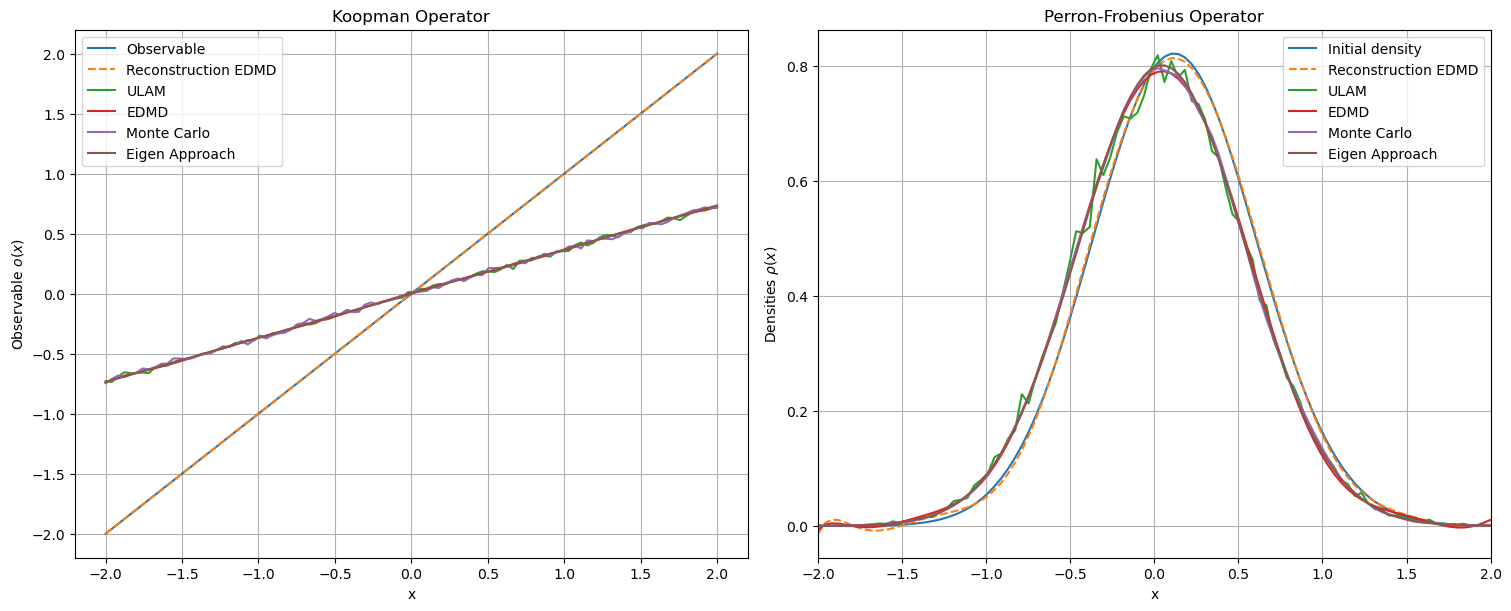

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)

# ==========================
# Observable comparison
# ==========================
ax = axes[0]

ax.plot(x, obs, label="Observable")
ax.plot(x, obs_rec, "--", label="Reconstruction EDMD")
ax.plot(x, obs_ulam, label="ULAM")
ax.plot(x, obs_edmd, label="EDMD")
ax.plot(x, obs_mc, label="Monte Carlo")
ax.plot(x, OU.eig_val(2, tau=1) * x, '-', label="Eigen Approach")
#ax.plot(x, ulam.K_dict["eigenvalue"][1].real * np.array([ulam.K_dict["eigenfunction"][1](np.array([xx]))for xx in x]).real, '--', label="Eigen Approach (ULAM)")
#ax.plot(x, edmd_M.K_dict["eigenvalue"][1].real * np.array([edmd_M.K_dict["eigenfunction"][1](np.array([xx]))for xx in x]).real, '--', label="Eigen Approach (ULAM)")
ax.set_title("Koopman Operator")
ax.set_xlabel("x")
ax.set_ylabel(r"Observable $o(x)$")
ax.grid(True)
ax.legend()

# ==========================
# Density comparison
# ==========================
ax = axes[1]

ax.plot(x, rho, label="Initial density")
ax.plot(x, rho_rec, "--", label="Reconstruction EDMD")
ax.plot(x, rho_ulam, label="ULAM")
ax.plot(x, rho_next, label="EDMD")
ax.plot(x, rho_MC, label="Monte Carlo")
ax.plot(x,rho_exact,label = "Eigen Approach")
ax.set_title("Perron-Frobenius Operator")
ax.set_xlabel("x")
ax.set_ylabel(r"Densities $\rho(x)$")
ax.set_xlim([-2, 2])
ax.grid(True)
ax.legend()

plt.show()

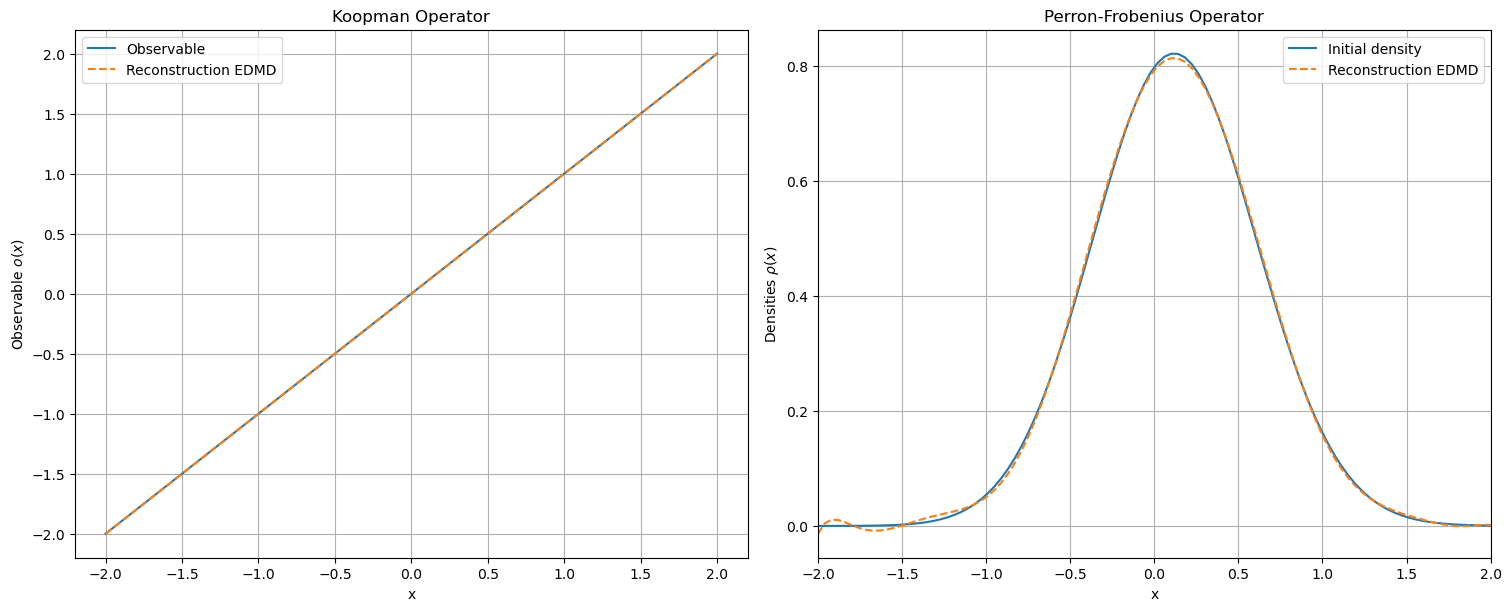

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)

# ==========================
# Observable comparison
# ==========================
ax = axes[0]

ax.plot(x, obs, label="Observable")
ax.plot(x, obs_rec, "--", label="Reconstruction EDMD")
#ax.plot(x, obs_ulam, label="ULAM")
#ax.plot(x, obs_edmd, label="EDMD")
#ax.plot(x, obs_mc, label="Monte Carlo")
#ax.plot(x, OU.eig_val(2, tau=1) * x, '-', label="Eigen Approach")
#ax.plot(x, ulam.K_dict["eigenvalue"][1].real * np.array([ulam.K_dict["eigenfunction"][1](np.array([xx]))for xx in x]).real, '--', label="Eigen Approach (ULAM)")
#ax.plot(x, edmd_M.K_dict["eigenvalue"][1].real * np.array([edmd_M.K_dict["eigenfunction"][1](np.array([xx]))for xx in x]).real, '--', label="Eigen Approach (ULAM)")
ax.set_title("Koopman Operator")
ax.set_xlabel("x")
ax.set_ylabel(r"Observable $o(x)$")
ax.grid(True)
ax.legend()

# ==========================
# Density comparison
# ==========================
ax = axes[1]

ax.plot(x, rho, label="Initial density")
ax.plot(x, rho_rec, "--", label="Reconstruction EDMD")
#ax.plot(x, rho_ulam, label="ULAM")
#ax.plot(x, rho_next, label="EDMD")
#ax.plot(x, rho_MC, label="Monte Carlo")
#ax.plot(x,rho_exact,label = "Eigen Approach")
ax.set_title("Perron-Frobenius Operator")
ax.set_xlabel("x")
ax.set_ylabel(r"Densities $\rho(x)$")
ax.set_xlim([-2, 2])
ax.grid(True)
ax.legend()

plt.show()

## Impact of number of size of dictionary

Simulating fast:   0%|          | 0/1000 [00:00<?, ?it/s]

Simulating fast: 100%|██████████| 1000/1000 [00:03<00:00, 330.62it/s]


Testing with 2 monomials...
Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 100000/100000 [00:03<00:00, 32789.81it/s]


G condition number: 10.30606340904422
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
3.36775124894445e-16
Computing eigenvalues, eigenvectors and eigenfunctions...


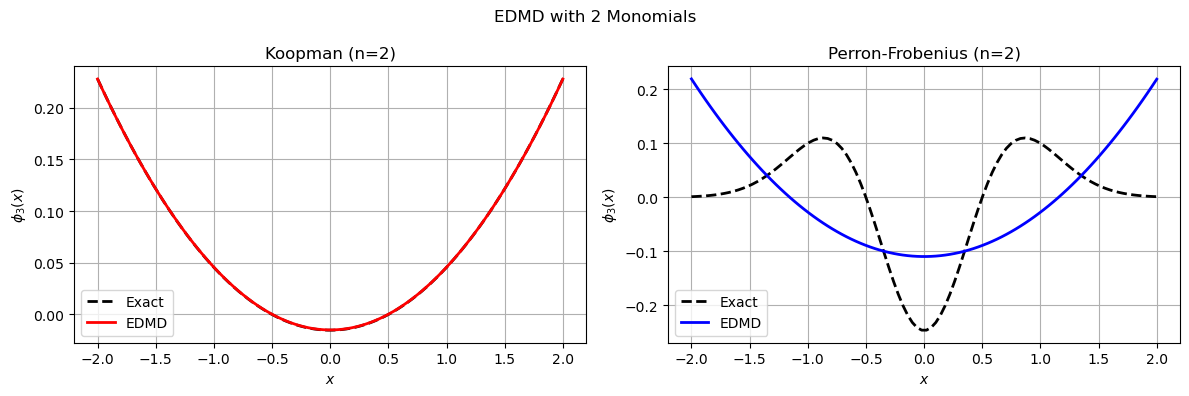

Testing with 4 monomials...
Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 100000/100000 [00:04<00:00, 20771.65it/s]


G condition number: 364.41350217419637
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
3.4513694594842364e-14
Computing eigenvalues, eigenvectors and eigenfunctions...


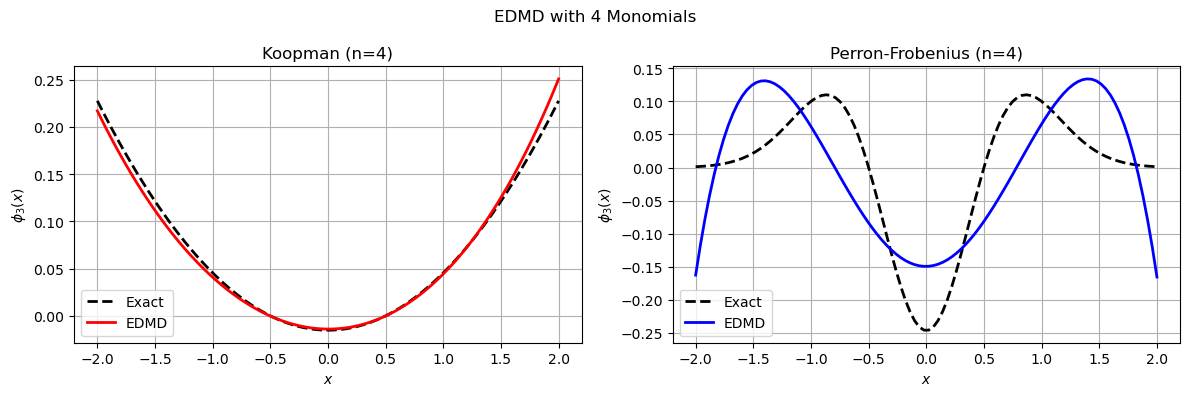

Testing with 6 monomials...
Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 100000/100000 [00:07<00:00, 14127.62it/s]


G condition number: 22769.87344661175
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
3.154923018349244e-11
Computing eigenvalues, eigenvectors and eigenfunctions...


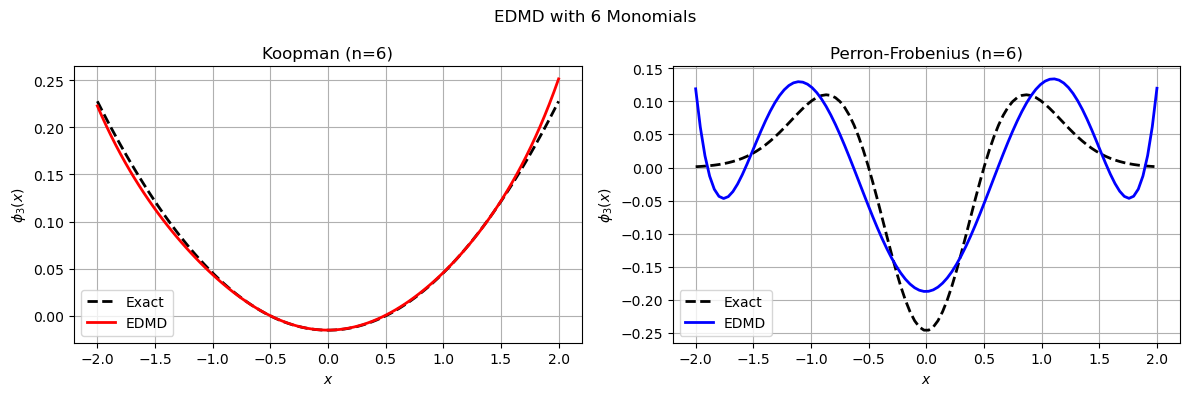

Testing with 8 monomials...
Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 100000/100000 [00:07<00:00, 12730.77it/s]


G condition number: 1643779.923125564
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
3.4580188582875565e-09
Computing eigenvalues, eigenvectors and eigenfunctions...


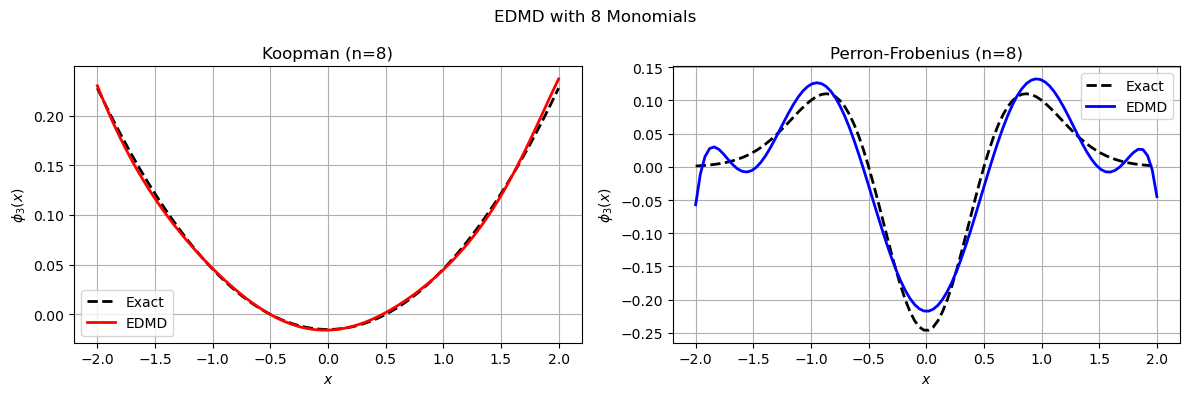

Testing with 10 monomials...
Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 100000/100000 [00:06<00:00, 14557.14it/s]


G condition number: 130170411.53296983
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
6.518133944067278e-06
Computing eigenvalues, eigenvectors and eigenfunctions...


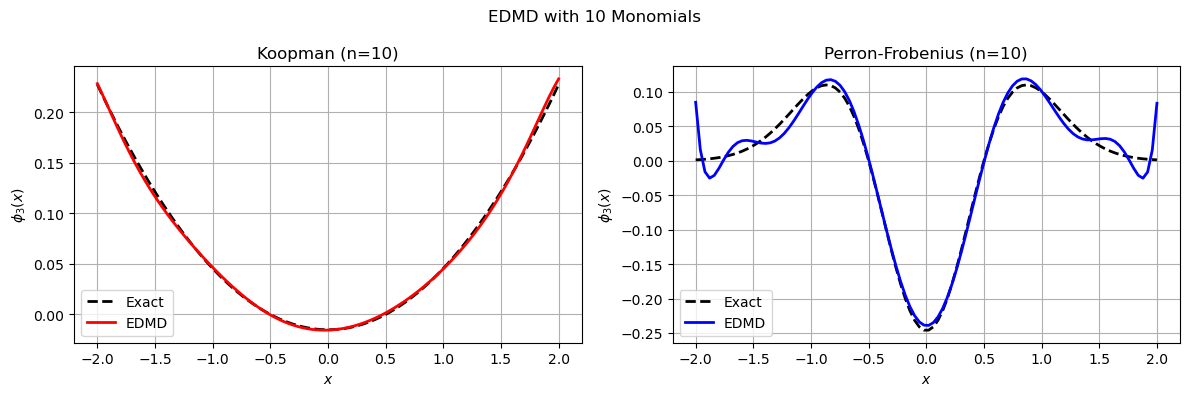

Testing with 12 monomials...
Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 100000/100000 [00:07<00:00, 13884.58it/s]


G condition number: 10943057859.174284
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
0.011542887910540109
Computing eigenvalues, eigenvectors and eigenfunctions...


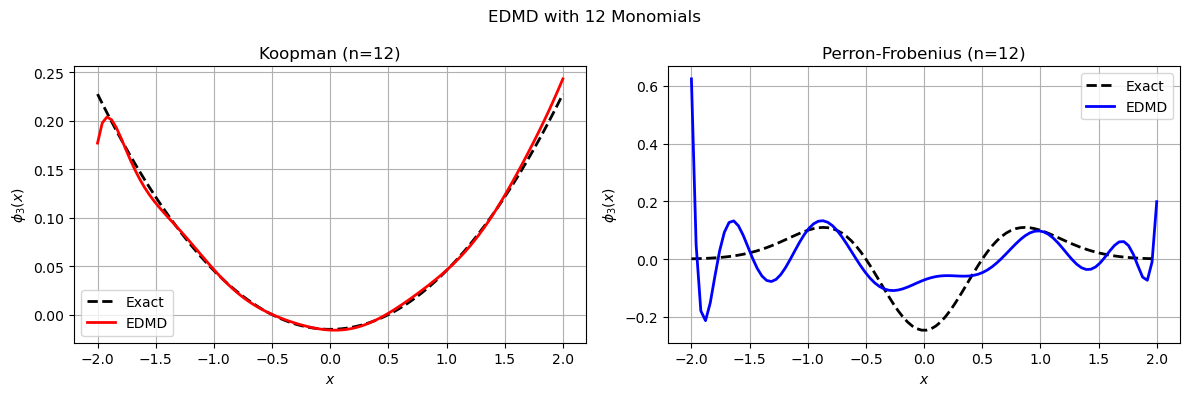

Testing with 14 monomials...
Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 100000/100000 [00:12<00:00, 8232.94it/s]


G condition number: 955307558289.1409
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
1.106099406984003
Computing eigenvalues, eigenvectors and eigenfunctions...


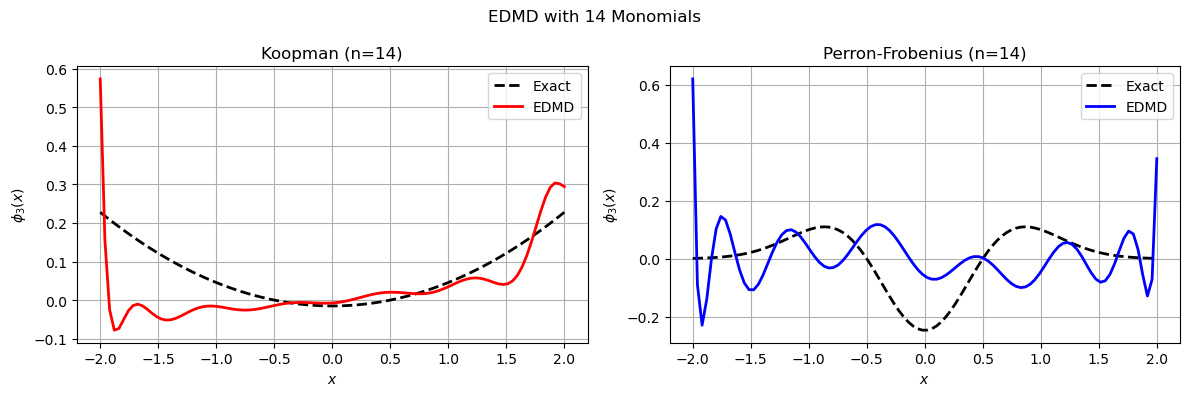

Testing with 16 monomials...
Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


 70%|██████▉   | 69740/100000 [00:07<00:03, 8924.91it/s] 


KeyboardInterrupt: 

In [27]:
ulam = sys.modules["ulam"].Ulam(Domain, N=[Nx], n_per_box=1000)

X = ulam.sample_points()

Y = OU.simulate_fast(
    x0=X,
    N=Nt,
    show_progress=True
)

# Number of monomials to test
poly_list = list(range(2, 18, 2))

max_err_K = []
max_err_P = []

l2_err_K = []
l2_err_P = []

eig_err_K = []
eig_err_P = []


# Grid spacing for L2 integral
dx = x[1] - x[0]


# Exact eigenfunctions
phi_exact_POP = OU.eig_func_POP(3, x).real
phi_exact_POP /= np.linalg.norm(phi_exact_POP)

phi_exact_KOP = OU.eig_func_KOP(3, x).real
phi_exact_KOP /= np.linalg.norm(phi_exact_KOP)


# Exact eigenvalue
lambda_exact = OU.eig_val(3, tau=Nt*h)


for n_poly in poly_list:

    print(f"Testing with {n_poly} monomials...")

    # Construct dictionary
    M = sys.modules["function_dictionary"].Monomials(
        n_poly,
        TotalDegree=False,
        dim=1
    )

    # Fit EDMD
    edmd_M = sys.modules["edmd"].EDMD()
    edmd_M.setup(X, Y, M)


    # -------------------------
    # Koopman eigenfunction
    # -------------------------
    phi_K = np.array([
        edmd_M.K_dict["eigenfunction"][2](np.array([xx]))
        for xx in x
    ]).real

    phi_K /= np.linalg.norm(phi_K)

    if np.dot(phi_exact_KOP, phi_K) < 0:
        phi_K = -phi_K


    # L-infinity error
    max_err_K.append(
        np.max(np.abs(phi_K - phi_exact_KOP))
    )

    # L2 error
    l2_err_K.append(
        np.sqrt(
            dx * np.sum((phi_K - phi_exact_KOP)**2)
        )
    )


    # Koopman eigenvalue error
    lambda_K = edmd_M.K_dict["eigenvalue"][2]

    eig_err_K.append(
        np.abs(lambda_K - lambda_exact)
    )



    # -------------------------
    # Perron-Frobenius eigenfunction
    # -------------------------
    phi_P = np.array([
        edmd_M.P_dict["eigenfunction"][2](np.array([xx]))
        for xx in x
    ]).real

    phi_P /= np.linalg.norm(phi_P)

    if np.dot(phi_exact_POP, phi_P) < 0:
        phi_P = -phi_P


    # L-infinity error
    max_err_P.append(
        np.max(np.abs(phi_P - phi_exact_POP))
    )

    # L2 error
    l2_err_P.append(
        np.sqrt(
            dx * np.sum((phi_P - phi_exact_POP)**2)
        )
    )


    # Perron-Frobenius eigenvalue error
    lambda_P = edmd_M.P_dict["eigenvalue"][2]

    eig_err_P.append(
        np.abs(lambda_P - lambda_exact)
    )


    # -------------------------
    # Plot eigenfunctions
    # -------------------------
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))


    # Koopman
    ax[0].plot(
        x,
        phi_exact_KOP,
        'k--',
        lw=2,
        label='Exact'
    )

    ax[0].plot(
        x,
        phi_K,
        'r',
        lw=2,
        label='EDMD'
    )

    ax[0].set_title(f'Koopman (n={n_poly})')
    ax[0].set_xlabel('$x$')
    ax[0].set_ylabel(r'$\phi_3(x)$')
    ax[0].grid(True)
    ax[0].legend()


    # Perron-Frobenius
    ax[1].plot(
        x,
        phi_exact_POP,
        'k--',
        lw=2,
        label='Exact'
    )

    ax[1].plot(
        x,
        phi_P,
        'b',
        lw=2,
        label='EDMD'
    )

    ax[1].set_title(f'Perron-Frobenius (n={n_poly})')
    ax[1].set_xlabel('$x$')
    ax[1].set_ylabel(r'$\phi_3(x)$')
    ax[1].grid(True)
    ax[1].legend()


    plt.suptitle(f'EDMD with {n_poly} Monomials')
    plt.tight_layout()
    plt.show()



# Convert to arrays
poly_list = np.asarray(poly_list)

max_err_K = np.asarray(max_err_K)
max_err_P = np.asarray(max_err_P)

l2_err_K = np.asarray(l2_err_K)
l2_err_P = np.asarray(l2_err_P)

eig_err_K = np.asarray(eig_err_K)
eig_err_P = np.asarray(eig_err_P)

### Eigenfunction Error

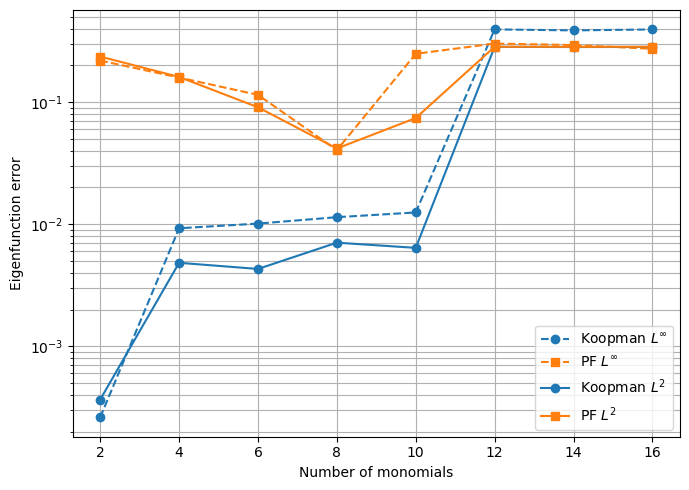

In [ ]:
plt.figure(figsize=(7,5))

plt.semilogy(poly_list, max_err_K, "o--",color = "C0", label=r"Koopman $L^\infty$")
plt.semilogy(poly_list, max_err_P, "s--", color = "C1", label=r"PF $L^\infty$")

plt.semilogy(poly_list, l2_err_K, "o-", color = "C0", label=r"Koopman $L^2$")
plt.semilogy(poly_list, l2_err_P, "s-", color = "C1", label=r"PF $L^2$")

plt.xlabel("Number of monomials")
plt.ylabel("Eigenfunction error")

plt.grid(True, which="both")
plt.legend()

plt.tight_layout()
plt.show()

### Eigenvalue

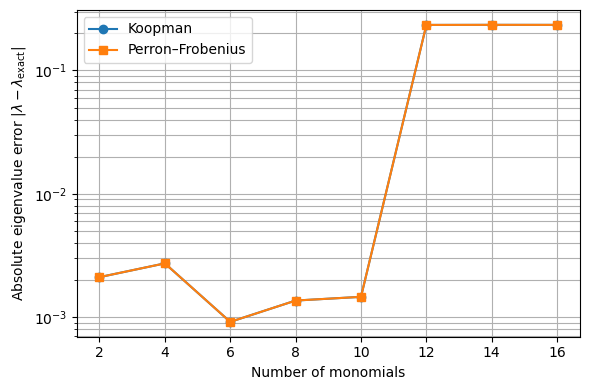

In [ ]:
# -------------------------
# Eigenvalue error plot
# -------------------------
plt.figure(figsize=(6,4))

plt.semilogy(poly_list, eig_err_K, "o-", label="Koopman")
plt.semilogy(poly_list, eig_err_P, "s-", label="Perron–Frobenius")

plt.xlabel("Number of monomials")
plt.ylabel(r"Absolute eigenvalue error $|\lambda-\lambda_{\mathrm{exact}}|$")
plt.grid(True, which="both")
plt.legend()

plt.tight_layout()
plt.show()

## Impact of number of samples per box

Exact eigenvalue: 0.1353352832366127

Running n_per_box = 1
Number of samples: (100, 1)


Building Ulam matrix (fast): 100%|██████████| 100/100 [00:00<00:00, 25929.18it/s]


Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 100/100 [00:00<00:00, 23158.88it/s]

G condition number: 10568844867.306952
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
0.0005440505924548417
Computing eigenvalues, eigenvectors and eigenfunctions...
Eigenvalues: [ 1. +0.j         0.5-0.8660254j  0.5+0.8660254j  0. +0.j
  0. +0.j         0. +0.j         0. +0.j         0. +0.j
  0. +0.j         0. +0.j         0. +0.j         0. +0.j
  0. +0.j         0. +0.j         0. +0.j         0. +0.j
  0. +0.j         0. +0.j         0. +0.j         0. +0.j
  0. +0.j         0. +0.j         0. +0.j         0. +0.j
  0. +0.j         0. +0.j         0. +0.j         0. +0.j
  0. +0.j         0. +0.j         0. +0.j         0. +0.j
  0. +0.j         0. +0.j         0. +0.j         0. +0.j
  0. +0.j         0. +0.j         0. +0.j         0. +0.j
  0. +0.j         0. +0.j         0. +0.j         0. +0.j
  0. +0.j         0. +0.j         0. +0.j         0. +0.j
  0. +0.j         0. +0.j         0. +0.j         0. +0.j
  0. +0.j         0. 

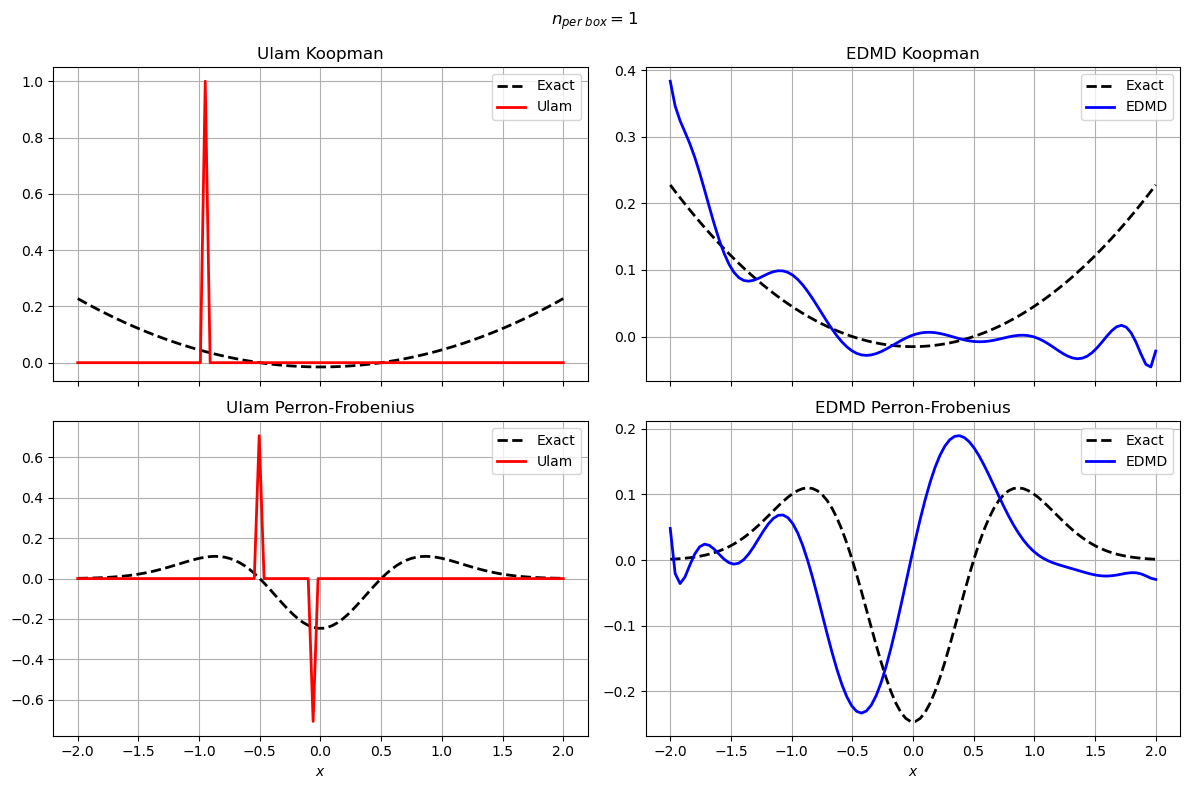


Running n_per_box = 10
Number of samples: (1000, 1)


Building Ulam matrix (fast): 100%|██████████| 1000/1000 [00:00<00:00, 41924.59it/s]


Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 1000/1000 [00:00<00:00, 27947.31it/s]

G condition number: 10978132427.430832
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
0.03984799568915456
Computing eigenvalues, eigenvectors and eigenfunctions...
Eigenvalues: [ 1.00000000e+00+0.00000000e+00j  4.27493697e-01+0.00000000e+00j
  2.72699098e-01+1.00831343e-01j  2.72699098e-01-1.00831343e-01j
  2.56016474e-01+0.00000000e+00j  2.35696709e-01+0.00000000e+00j
  2.03099703e-01-1.54768760e-01j  2.03099703e-01+1.54768760e-01j
  2.01295674e-01+9.37183576e-02j  2.01295674e-01-9.37183576e-02j
  1.75840794e-01+1.99690182e-01j  1.75840794e-01-1.99690182e-01j
  1.59478072e-01+2.12471829e-02j  1.59478072e-01-2.12471829e-02j
  1.09338734e-01-2.94314622e-02j  1.09338734e-01+2.94314622e-02j
  1.04851503e-01+1.49450533e-01j  1.04851503e-01-1.49450533e-01j
  1.02394245e-01+0.00000000e+00j  1.00000004e-01+0.00000000e+00j
  1.00000000e-01+0.00000000e+00j  1.00000000e-01+0.00000000e+00j
  9.99999959e-02+0.00000000e+00j  7.47829648e-02+1.25553650e-0

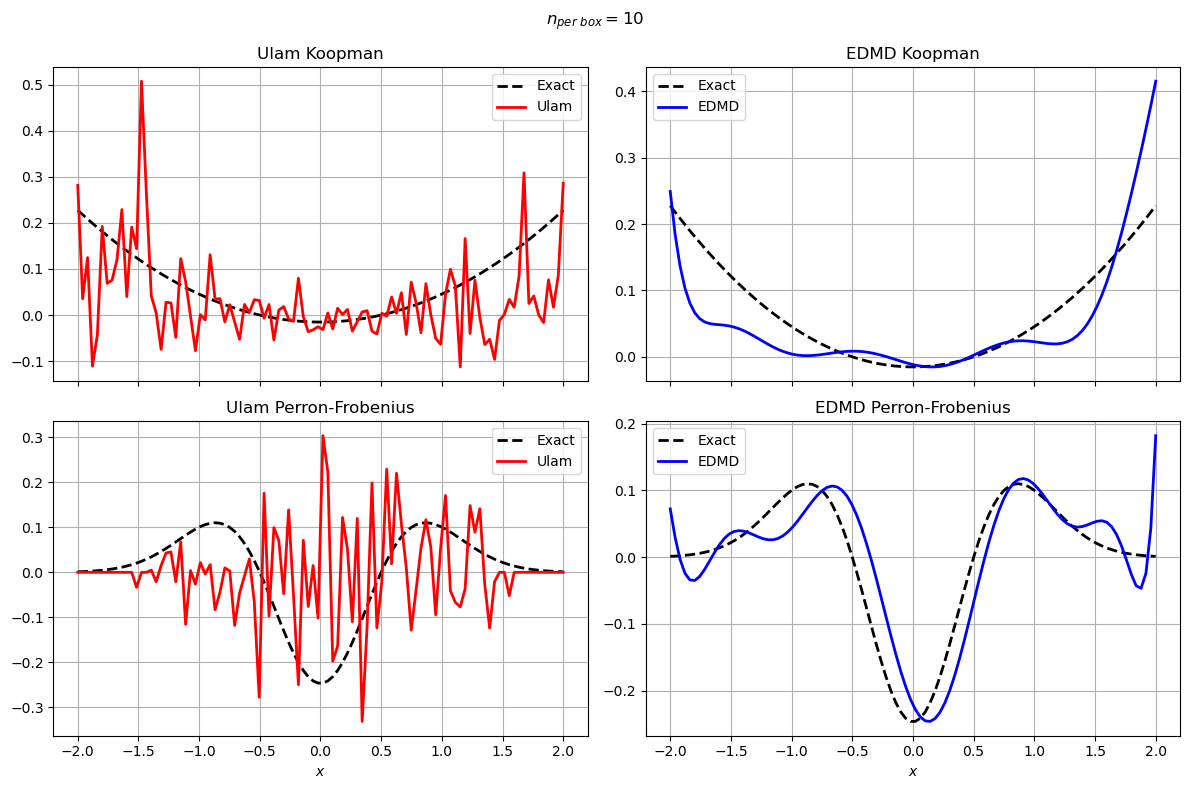


Running n_per_box = 100
Number of samples: (10000, 1)


Building Ulam matrix (fast): 100%|██████████| 10000/10000 [00:00<00:00, 43862.74it/s]


Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 10000/10000 [00:00<00:00, 28229.00it/s]


G condition number: 10965720878.670816
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
0.001296324721837207
Computing eigenvalues, eigenvectors and eigenfunctions...
Eigenvalues: [ 1.00000000e+00+0.j          3.58114843e-01+0.j
  1.39729261e-01+0.j          9.86860180e-02+0.j
  9.23710503e-02+0.j          9.02109098e-02+0.03745489j
  9.02109098e-02-0.03745489j  6.01545558e-02+0.j
  5.76066068e-02+0.04221793j  5.76066068e-02-0.04221793j
  5.42259295e-02+0.05926268j  5.42259295e-02-0.05926268j
  4.78780643e-02-0.03908277j  4.78780643e-02+0.03908277j
  4.73501540e-02-0.08267867j  4.73501540e-02+0.08267867j
  4.62123025e-02-0.00499212j  4.62123025e-02+0.00499212j
  4.50966709e-02+0.02130459j  4.50966709e-02-0.02130459j
  4.10206294e-02+0.j          3.51299256e-02-0.02797234j
  3.51299256e-02+0.02797234j  3.05043434e-02+0.07431437j
  3.05043434e-02-0.07431437j  2.55466953e-02+0.05198655j
  2.55466953e-02-0.05198655j  2.38849159e-02+0.02542621j
  

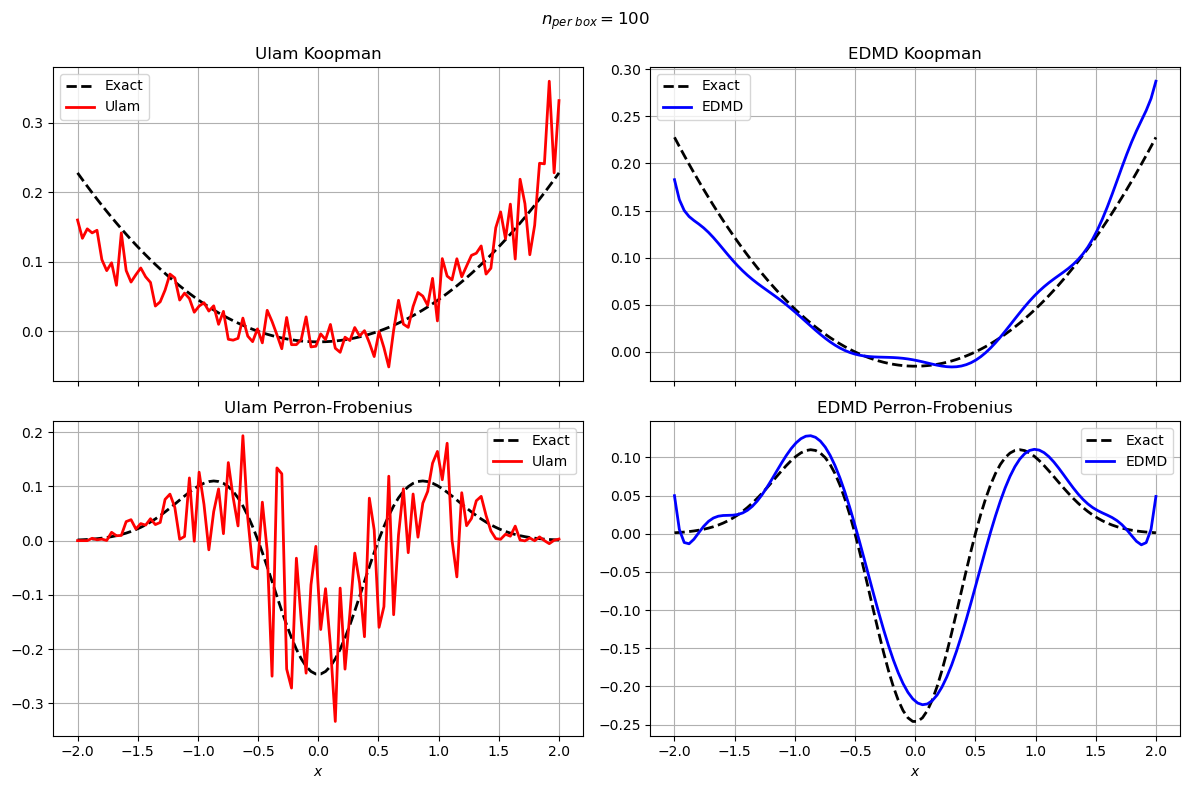


Running n_per_box = 1000
Number of samples: (100000, 1)


Building Ulam matrix (fast): 100%|██████████| 100000/100000 [00:02<00:00, 42802.72it/s]


Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 100000/100000 [00:03<00:00, 27696.11it/s]


G condition number: 10913160185.736801
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
0.007971791941875637
Computing eigenvalues, eigenvectors and eigenfunctions...
Eigenvalues: [ 1.00000000e+00+0.j          3.66540743e-01+0.j
  1.37289827e-01+0.j          5.05557750e-02+0.j
  3.24594418e-02+0.j          2.36410076e-02-0.0055447j
  2.36410076e-02+0.0055447j   2.22069134e-02+0.j
  2.11357898e-02+0.01078967j  2.11357898e-02-0.01078967j
  2.02441191e-02-0.0071333j   2.02441191e-02+0.0071333j
  1.69528329e-02-0.00518398j  1.69528329e-02+0.00518398j
  1.57670153e-02+0.j          1.48518216e-02+0.01918493j
  1.48518216e-02-0.01918493j  1.45944985e-02+0.01416264j
  1.45944985e-02-0.01416264j  1.32908002e-02+0.j
  1.31711239e-02+0.00922917j  1.31711239e-02-0.00922917j
  1.17506846e-02-0.00581179j  1.17506846e-02+0.00581179j
  1.01020992e-02-0.02647001j  1.01020992e-02+0.02647001j
  7.12351981e-03-0.01029435j  7.12351981e-03+0.01029435j
  6.70738979

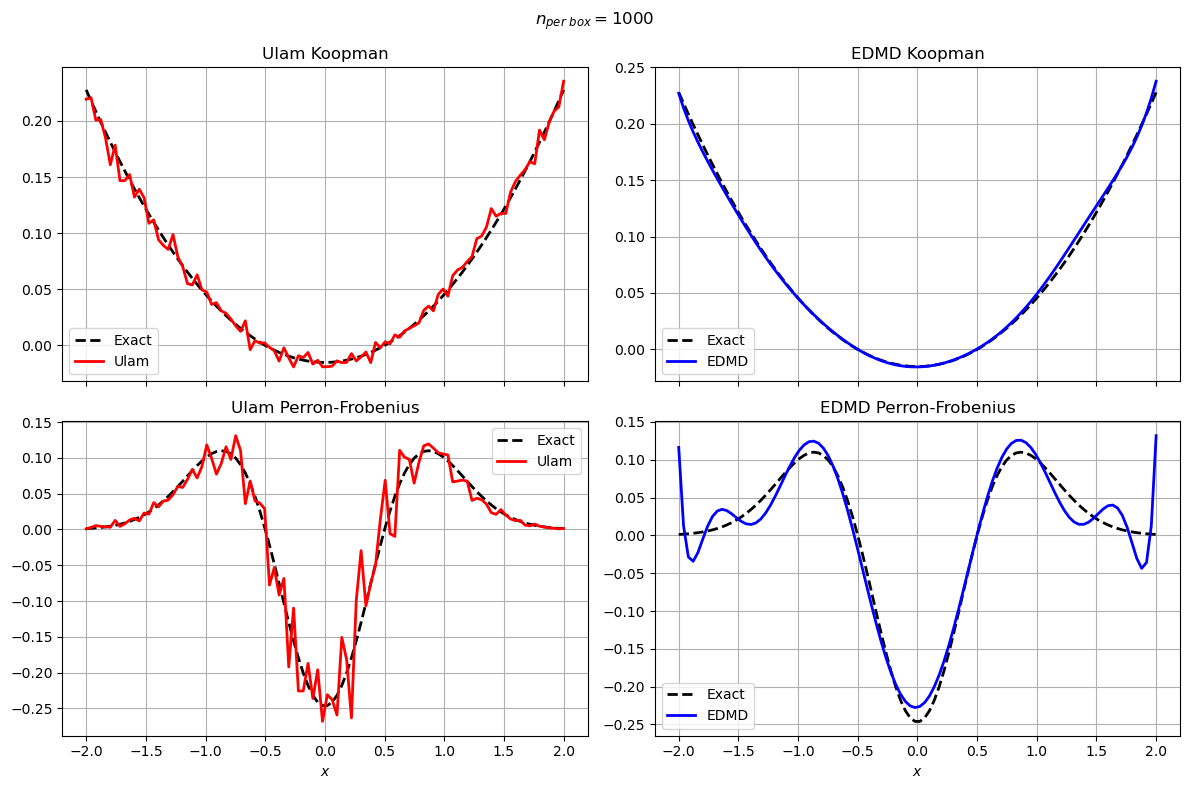


Running n_per_box = 10000
Number of samples: (1000000, 1)


Building Ulam matrix (fast): 100%|██████████| 1000000/1000000 [00:23<00:00, 43311.51it/s]


Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


 57%|█████▋    | 565252/1000000 [00:20<00:15, 27383.59it/s]


KeyboardInterrupt: 

In [ ]:
n_per_box_list = [1, 10, 100, 1000, 10000]
n_poly = 12
x = np.linspace(xmin, xmax, Nx)
dx = x[1] - x[0]

# ==========================================================
# Error storage
# ==========================================================
err_ulam_K = []
err_ulam_P = []
err_edmd_K = []
err_edmd_P = []

eig_err_ulam_K = []
eig_err_ulam_P = []
eig_err_edmd_K = []
eig_err_edmd_P = []


# Eigenfunction L2 errors
l2_err_ulam_K = []
l2_err_ulam_P = []
l2_err_edmd_K = []
l2_err_edmd_P = []

# ==========================================================
# Exact eigenfunctions
# ==========================================================
phi_exact_POP = OU.eig_func_POP(3, x).real
phi_exact_POP /= np.linalg.norm(phi_exact_POP)

phi_exact_KOP = OU.eig_func_KOP(3, x).real
phi_exact_KOP /= np.linalg.norm(phi_exact_KOP)


# Exact eigenvalue
lambda_exact = OU.eig_val(3, tau=Nt*h)

print("Exact eigenvalue:", lambda_exact)


# ==========================================================
# Dictionary
# ==========================================================
M = sys.modules["function_dictionary"].Monomials(
    n_poly,
    TotalDegree=False,
    dim=1
)


# ==========================================================
# Helper function
# ==========================================================
def get_matching_eigenfunction(operator_dict, lambda_target, x):

    eigvals = np.asarray(operator_dict["eigenvalue"])

    print("Eigenvalues:", eigvals)

    # choose eigenvalue closest to analytical one
    idx = np.argmin(np.abs(eigvals - lambda_target))

    lam = eigvals[idx]

    print(
        f"Selected eigenvalue = {lam.real:.8f}, "
        f"index = {idx}"
    )

    phi = np.array([
        operator_dict["eigenfunction"][idx](np.array([xx]))
        for xx in x
    ]).real

    return phi, lam, idx



# ==========================================================
# Main loop
# ==========================================================
for n_per_box in n_per_box_list:

    print("\n================================")
    print(f"Running n_per_box = {n_per_box}")
    print("================================")


    # ---------------------------------
    # Generate data
    # ---------------------------------
    ulam = sys.modules["ulam"].Ulam(
        Domain,
        N=[Nx],
        n_per_box=n_per_box
    )

    X = ulam.sample_points()

    print("Number of samples:", X.shape)


    Y = OU.simulate_fast(
        x0=X,
        N=Nt,
        show_progress=True
    )


    # ---------------------------------
    # Ulam
    # ---------------------------------
    ulam.setup(
        X=X,
        Y=Y
    )


    # ---------------------------------
    # EDMD
    # ---------------------------------
    edmd_M = sys.modules["edmd"].EDMD()

    edmd_M.setup(
        X,
        Y,
        M
    )


    # ======================================================
    # Ulam Koopman
    # ======================================================
    phi_ulam_K, lambda_ulam_K, idx_ulam_K = \
        get_matching_eigenfunction(
            ulam.K_dict,
            lambda_exact,
            x
        )

    phi_ulam_K /= np.linalg.norm(phi_ulam_K)

    if np.dot(phi_exact_KOP, phi_ulam_K) < 0:
        phi_ulam_K *= -1


    err_ulam_K.append(
        np.max(np.abs(phi_ulam_K - phi_exact_KOP))
    )

    l2_err_ulam_K.append(
        np.sqrt(
            dx * np.sum((phi_ulam_K - phi_exact_KOP)**2)
        )
    )

    eig_err_ulam_K.append(
        abs(lambda_ulam_K - lambda_exact)
    )



    # ======================================================
    # Ulam Perron-Frobenius
    # ======================================================
    phi_ulam_P, lambda_ulam_P, idx_ulam_P = \
        get_matching_eigenfunction(
            ulam.P_dict,
            lambda_exact,
            x
        )

    phi_ulam_P /= np.linalg.norm(phi_ulam_P)

    if np.dot(phi_exact_POP, phi_ulam_P) < 0:
        phi_ulam_P *= -1


    err_ulam_P.append(
        np.max(np.abs(phi_ulam_P - phi_exact_POP))
    )

    l2_err_ulam_P.append(
        np.sqrt(
            dx * np.sum((phi_ulam_P - phi_exact_POP)**2)
        )
    )

    eig_err_ulam_P.append(
        abs(lambda_ulam_P - lambda_exact)
    )



    # ======================================================
    # EDMD Koopman
    # ======================================================
    phi_edmd_K, lambda_edmd_K, idx_edmd_K = \
        get_matching_eigenfunction(
            edmd_M.K_dict,
            lambda_exact,
            x
        )

    phi_edmd_K /= np.linalg.norm(phi_edmd_K)

    if np.dot(phi_exact_KOP, phi_edmd_K) < 0:
        phi_edmd_K *= -1


    err_edmd_K.append(
        np.max(np.abs(phi_edmd_K - phi_exact_KOP))
    )

    l2_err_edmd_K.append(
        np.sqrt(
            dx * np.sum((phi_edmd_K - phi_exact_KOP)**2)
        )
    )
    eig_err_edmd_K.append(
        abs(lambda_edmd_K - lambda_exact)
    )



    # ======================================================
    # EDMD Perron-Frobenius
    # ======================================================
    phi_edmd_P, lambda_edmd_P, idx_edmd_P = \
        get_matching_eigenfunction(
            edmd_M.P_dict,
            lambda_exact,
            x
        )

    phi_edmd_P /= np.linalg.norm(phi_edmd_P)

    if np.dot(phi_exact_POP, phi_edmd_P) < 0:
        phi_edmd_P *= -1


    err_edmd_P.append(
        np.max(np.abs(phi_edmd_P - phi_exact_POP))
    )

    l2_err_edmd_P.append(
        np.sqrt(
            dx * np.sum((phi_edmd_P - phi_exact_POP)**2)
        )
    )    

    eig_err_edmd_P.append(
        abs(lambda_edmd_P - lambda_exact)
    )



    # ======================================================
    # Plot eigenfunctions
    # ======================================================
    fig, ax = plt.subplots(
        2,
        2,
        figsize=(12,8),
        sharex=True
    )


    # -------------------------
    # Ulam Koopman
    # -------------------------
    ax[0,0].plot(
        x,
        phi_exact_KOP,
        'k--',
        lw=2,
        label="Exact"
    )

    ax[0,0].plot(
        x,
        phi_ulam_K,
        'r',
        lw=2,
        label="Ulam"
    )

    ax[0,0].set_title("Ulam Koopman")
    ax[0,0].grid()
    ax[0,0].legend()



    # -------------------------
    # EDMD Koopman
    # -------------------------
    ax[0,1].plot(
        x,
        phi_exact_KOP,
        'k--',
        lw=2,
        label="Exact"
    )

    ax[0,1].plot(
        x,
        phi_edmd_K,
        'b',
        lw=2,
        label="EDMD"
    )

    ax[0,1].set_title("EDMD Koopman")
    ax[0,1].grid()
    ax[0,1].legend()



    # -------------------------
    # Ulam PF
    # -------------------------
    ax[1,0].plot(
        x,
        phi_exact_POP,
        'k--',
        lw=2,
        label="Exact"
    )

    ax[1,0].plot(
        x,
        phi_ulam_P,
        'r',
        lw=2,
        label="Ulam"
    )

    ax[1,0].set_title("Ulam Perron-Frobenius")
    ax[1,0].set_xlabel("$x$")
    ax[1,0].grid()
    ax[1,0].legend()



    # -------------------------
    # EDMD PF
    # -------------------------
    ax[1,1].plot(
        x,
        phi_exact_POP,
        'k--',
        lw=2,
        label="Exact"
    )

    ax[1,1].plot(
        x,
        phi_edmd_P,
        'b',
        lw=2,
        label="EDMD"
    )

    ax[1,1].set_title("EDMD Perron-Frobenius")
    ax[1,1].set_xlabel("$x$")
    ax[1,1].grid()
    ax[1,1].legend()


    plt.suptitle(
        rf"$n_{{per\ box}}={n_per_box}$"
    )

    plt.tight_layout()
    plt.show()



# ==========================================================
# Convert to arrays
# ==========================================================
n_per_box_list = np.asarray(n_per_box_list)

err_ulam_K = np.asarray(err_ulam_K)
err_ulam_P = np.asarray(err_ulam_P)

err_edmd_K = np.asarray(err_edmd_K)
err_edmd_P = np.asarray(err_edmd_P)


eig_err_ulam_K = np.asarray(eig_err_ulam_K)
eig_err_ulam_P = np.asarray(eig_err_ulam_P)

eig_err_edmd_K = np.asarray(eig_err_edmd_K)
eig_err_edmd_P = np.asarray(eig_err_edmd_P)

l2_err_ulam_K = np.asarray(l2_err_ulam_K)
l2_err_ulam_P = np.asarray(l2_err_ulam_P)
l2_err_edmd_K = np.asarray(l2_err_edmd_K)
l2_err_edmd_P = np.asarray(l2_err_edmd_P)

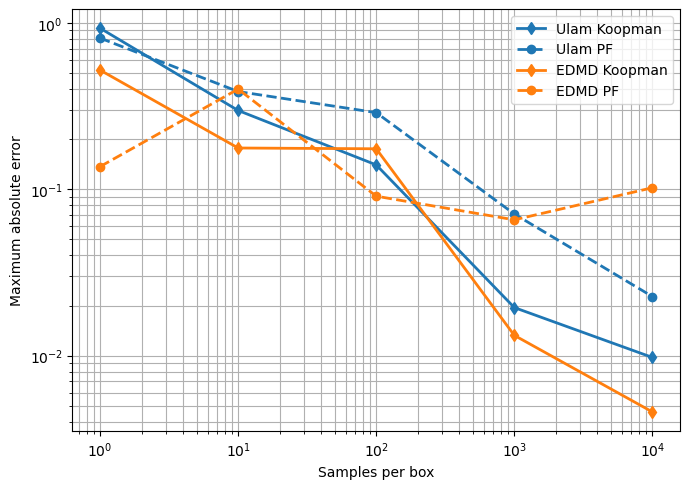

In [ ]:
plt.figure(figsize=(7,5))

plt.loglog(n_per_box_list, err_ulam_K, "d-", color="C0", lw=2, label="Ulam Koopman")
plt.loglog(n_per_box_list, err_ulam_P, "o--", color="C0", lw=2, label="Ulam PF")

plt.loglog(n_per_box_list, err_edmd_K, "d-", color="C1", lw=2, label="EDMD Koopman")
plt.loglog(n_per_box_list, err_edmd_P, "o--", color="C1", lw=2, label="EDMD PF")

plt.xlabel("Samples per box")
plt.ylabel("Maximum absolute error")
plt.grid(True, which="both")
plt.legend()

plt.tight_layout()
plt.show()

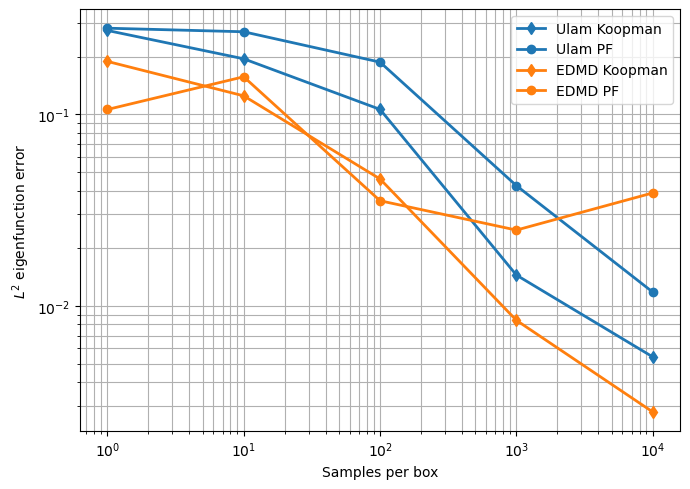

In [ ]:
plt.figure(figsize=(7,5))

plt.loglog(
    n_per_box_list,
    l2_err_ulam_K,
    "d-",
    color="C0",
    lw=2,
    label="Ulam Koopman"
)

plt.loglog(
    n_per_box_list,
    l2_err_ulam_P,
    "o-",
    color="C0",
    lw=2,
    label="Ulam PF"
)

plt.loglog(
    n_per_box_list,
    l2_err_edmd_K,
    "d-",
    color="C1",
    lw=2,
    label="EDMD Koopman"
)

plt.loglog(
    n_per_box_list,
    l2_err_edmd_P,
    "o-",
    color="C1",
    lw=2,
    label="EDMD PF"
)

plt.xlabel("Samples per box")
plt.ylabel(r"$L^2$ eigenfunction error")

plt.grid(True, which="both")
plt.legend()

plt.tight_layout()
plt.show()

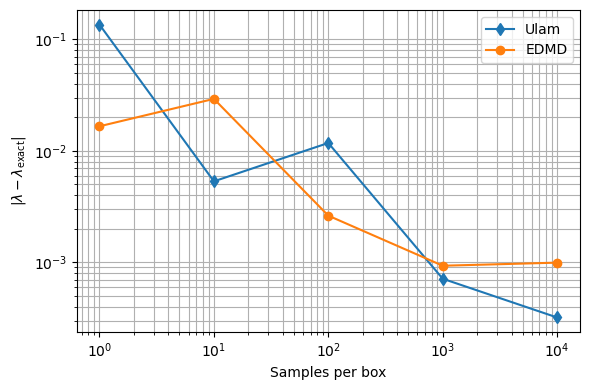

In [ ]:
plt.figure(figsize=(6,4))

plt.loglog(n_per_box_list, eig_err_ulam_K, "d-", color="C0", label="Ulam")
plt.loglog(n_per_box_list, eig_err_edmd_K, "o-", color="C1", label="EDMD")


plt.xlabel("Samples per box")
plt.ylabel(r"$|\lambda-\lambda_{\rm exact}|$")
plt.grid(True, which="both")
plt.legend()

plt.tight_layout()
plt.show()

# Impact of samples 2


n_per_box = 1


Building Ulam matrix (fast): 100%|██████████| 100/100 [00:00<00:00, 21124.67it/s]


Saved to c:\Users\wagne\OneDrive\Dokumente\Universität\Master_Elektrotechnik\3.Semester\Forschungspraktikum\Code\K_PF_time_homogeneous_Markovian_RDS\Notebooks\Monomials.png
Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 100/100 [00:00<00:00, 18718.72it/s]

G condition number: 124701658.94670165
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
9.065136079938017e-07
Computing eigenvalues, eigenvectors and eigenfunctions...


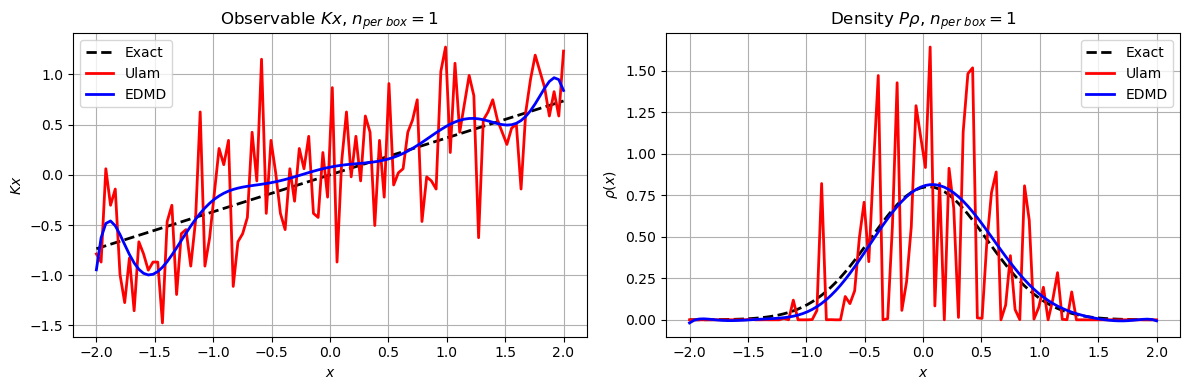


n_per_box = 10


Building Ulam matrix (fast): 100%|██████████| 1000/1000 [00:00<00:00, 40517.63it/s]


Saved to c:\Users\wagne\OneDrive\Dokumente\Universität\Master_Elektrotechnik\3.Semester\Forschungspraktikum\Code\K_PF_time_homogeneous_Markovian_RDS\Notebooks\Monomials.png
Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 1000/1000 [00:00<00:00, 31217.14it/s]

G condition number: 130812490.57689151
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
4.704472314775564e-07
Computing eigenvalues, eigenvectors and eigenfunctions...


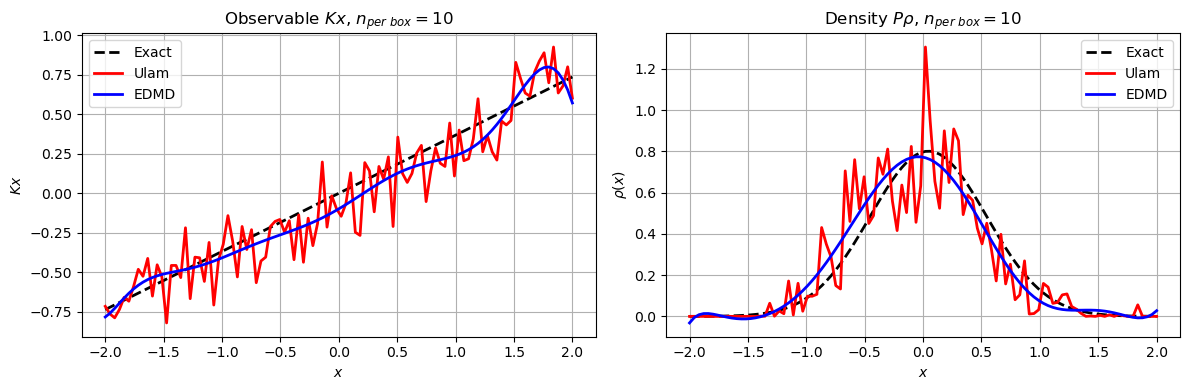


n_per_box = 100


Building Ulam matrix (fast): 100%|██████████| 10000/10000 [00:00<00:00, 34733.91it/s]


Saved to c:\Users\wagne\OneDrive\Dokumente\Universität\Master_Elektrotechnik\3.Semester\Forschungspraktikum\Code\K_PF_time_homogeneous_Markovian_RDS\Notebooks\Monomials.png
Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 10000/10000 [00:00<00:00, 25510.47it/s]


G condition number: 130298328.9211186
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
7.452527674267928e-06
Computing eigenvalues, eigenvectors and eigenfunctions...


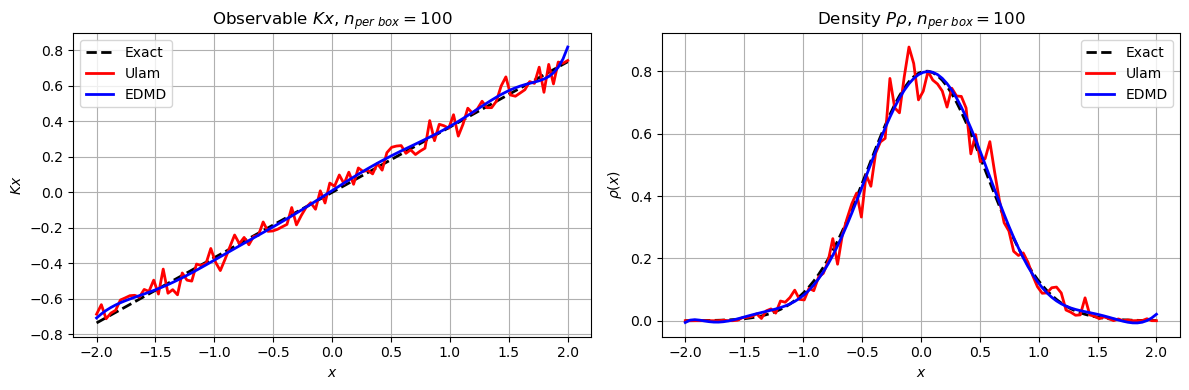


n_per_box = 1000


Building Ulam matrix (fast): 100%|██████████| 100000/100000 [00:02<00:00, 33736.83it/s]


Saved to c:\Users\wagne\OneDrive\Dokumente\Universität\Master_Elektrotechnik\3.Semester\Forschungspraktikum\Code\K_PF_time_homogeneous_Markovian_RDS\Notebooks\Monomials.png
Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 100000/100000 [00:03<00:00, 25521.84it/s]


G condition number: 130494257.17479168
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
4.977581722010652e-06
Computing eigenvalues, eigenvectors and eigenfunctions...


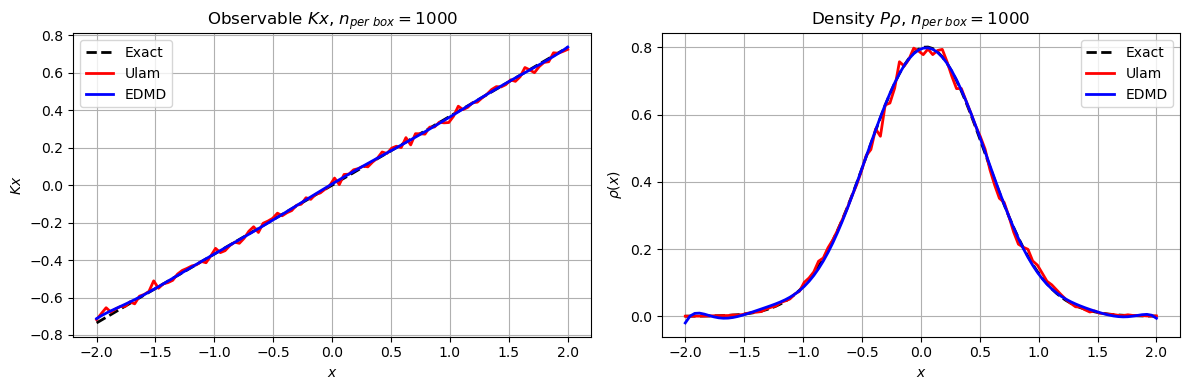


n_per_box = 10000


Building Ulam matrix (fast): 100%|██████████| 1000000/1000000 [00:27<00:00, 35846.10it/s]


Saved to c:\Users\wagne\OneDrive\Dokumente\Universität\Master_Elektrotechnik\3.Semester\Forschungspraktikum\Code\K_PF_time_homogeneous_Markovian_RDS\Notebooks\Monomials.png
Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 1000000/1000000 [00:39<00:00, 25470.82it/s]


G condition number: 130255123.2279908
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
8.75088778933922e-06
Computing eigenvalues, eigenvectors and eigenfunctions...


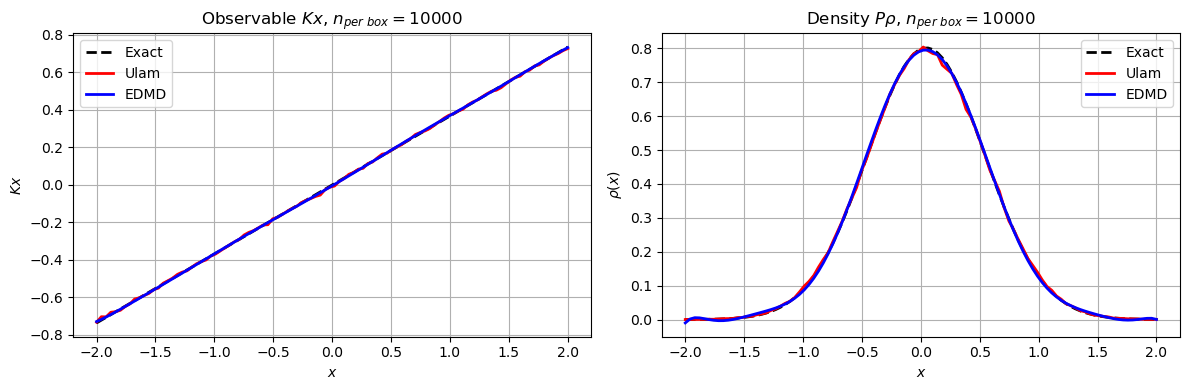

In [ ]:
n_per_box_list = [1, 10, 100, 1000, 10000]


# ==========================================================
# Error storage
# ==========================================================

# Observable
obs_linf_ulam = []
obs_linf_edmd = []

obs_l2_ulam = []
obs_l2_edmd = []


# Density
rho_linf_ulam = []
rho_linf_edmd = []

rho_l2_ulam = []
rho_l2_edmd = []

rho_KL_ulam = []
rho_KL_edmd = []


# grid
x = np.linspace(xmin, xmax, Nx)

dx = x[1]-x[0]


# ==========================================================
# True observable
# ==========================================================

obs = x

obs_true = OU.eig_val(
    2,
    tau=1
) * x



# ==========================================================
# Initial density
# ==========================================================

rho = (
    OU.eig_func_POP(1,x)
    +
    0.25*OU.eig_func_POP(2,x)
)

rho = np.maximum(rho,0)

rho /= np.trapezoid(rho,x)


rho_exact = (
    OU.eig_val(1,tau=1)
    *
    OU.eig_func_POP(1,x)
    +
    OU.eig_val(2,tau=1)
    *
    0.25
    *
    OU.eig_func_POP(2,x)
)

rho_exact = np.maximum(rho_exact,0)

rho_exact /= np.trapezoid(rho_exact,x)



# ==========================================================
# KL function
# ==========================================================

def KL_divergence(p,q,x):

    eps = 1e-14

    p = np.maximum(p,eps)
    q = np.maximum(q,eps)

    return np.trapezoid(
        p*np.log(p/q),
        x
    )



# ==========================================================
# Main loop
# ==========================================================

for n_per_box in n_per_box_list:

    print("\n============================")
    print("n_per_box =", n_per_box)
    print("============================")


    # ----------------------------------
    # Generate data
    # ----------------------------------

    ulam = sys.modules["ulam"].Ulam(
        Domain,
        N=[Nx],
        n_per_box=n_per_box
    )


    X = ulam.sample_points()


    Y = OU.simulate_fast(
        x0=X,
        N=Nt,
        show_progress=False
    )


    # Ulam
    ulam.setup(
        X=X,
        Y=Y
    )


    # EDMD
    M = sys.modules["function_dictionary"].Monomials(
        10,
        TotalDegree=False,
        dim=1
    )

    edmd_M = sys.modules["edmd"].EDMD()

    edmd_M.setup(
        X,
        Y,
        M
    )


    # ======================================================
    # Observable
    # ======================================================


    obs_ulam = ulam.apply_K(obs)


    obs_edmd = edmd_M.apply_K(
        obs,
        x
    )


    # L infinity

    obs_linf_ulam.append(
        np.max(
            np.abs(obs_ulam-obs_true)
        )
    )


    obs_linf_edmd.append(
        np.max(
            np.abs(obs_edmd-obs_true)
        )
    )


    # L2

    obs_l2_ulam.append(
        np.sqrt(
            dx*np.sum(
                (obs_ulam-obs_true)**2
            )
        )
    )


    obs_l2_edmd.append(
        np.sqrt(
            dx*np.sum(
                (obs_edmd-obs_true)**2
            )
        )
    )



    # ======================================================
    # Density
    # ======================================================


    rho_ulam = ulam.apply_P(rho)

    rho_ulam /= np.trapezoid(
        rho_ulam,
        x
    )


    rho_edmd = edmd_M.apply_P(
        rho,
        x
    )

    rho_edmd /= np.trapezoid(
        rho_edmd,
        x
    )


    # ----------------------------
    # L infinity
    # ----------------------------

    rho_linf_ulam.append(
        np.max(
            np.abs(rho_ulam-rho_exact)
        )
    )


    rho_linf_edmd.append(
        np.max(
            np.abs(rho_edmd-rho_exact)
        )
    )


    # ----------------------------
    # L2
    # ----------------------------

    rho_l2_ulam.append(
        np.sqrt(
            dx*np.sum(
                (rho_ulam-rho_exact)**2
            )
        )
    )


    rho_l2_edmd.append(
        np.sqrt(
            dx*np.sum(
                (rho_edmd-rho_exact)**2
            )
        )
    )


    # ----------------------------
    # KL
    # ----------------------------

    rho_KL_ulam.append(
        KL_divergence(
            rho_exact,
            rho_ulam,
            x
        )
    )


    rho_KL_edmd.append(
        KL_divergence(
            rho_exact,
            rho_edmd,
            x
        )
    )

    # ======================================================
    # Plot observable and density for this n_per_box
    # ======================================================

    fig, ax = plt.subplots(
        1,
        2,
        figsize=(12,4)
    )


    # ------------------------------------------------------
    # Observable
    # ------------------------------------------------------

    ax[0].plot(
        x,
        obs_true,
        'k--',
        lw=2,
        label="Exact"
    )

    ax[0].plot(
        x,
        obs_ulam,
        'r',
        lw=2,
        label="Ulam"
    )

    ax[0].plot(
        x,
        obs_edmd,
        'b',
        lw=2,
        label="EDMD"
    )

    ax[0].set_title(
        f"Observable $Kx$, $n_{{per\\ box}}={n_per_box}$"
    )

    ax[0].set_xlabel("$x$")
    ax[0].set_ylabel("$Kx$")
    ax[0].grid(True)
    ax[0].legend()



    # ------------------------------------------------------
    # Density
    # ------------------------------------------------------

    ax[1].plot(
        x,
        rho_exact,
        'k--',
        lw=2,
        label="Exact"
    )

    ax[1].plot(
        x,
        rho_ulam,
        'r',
        lw=2,
        label="Ulam"
    )

    ax[1].plot(
        x,
        rho_edmd,
        'b',
        lw=2,
        label="EDMD"
    )


    ax[1].set_title(
        f"Density $P\\rho$, $n_{{per\\ box}}={n_per_box}$"
    )

    ax[1].set_xlabel("$x$")
    ax[1].set_ylabel("$\\rho(x)$")
    ax[1].grid(True)
    ax[1].legend()


    plt.tight_layout()
    plt.show()


# convert arrays

n_per_box_list=np.asarray(n_per_box_list)


obs_linf_ulam=np.asarray(obs_linf_ulam)
obs_linf_edmd=np.asarray(obs_linf_edmd)

obs_l2_ulam=np.asarray(obs_l2_ulam)
obs_l2_edmd=np.asarray(obs_l2_edmd)


rho_linf_ulam=np.asarray(rho_linf_ulam)
rho_linf_edmd=np.asarray(rho_linf_edmd)

rho_l2_ulam=np.asarray(rho_l2_ulam)
rho_l2_edmd=np.asarray(rho_l2_edmd)

rho_KL_ulam=np.asarray(rho_KL_ulam)
rho_KL_edmd=np.asarray(rho_KL_edmd)

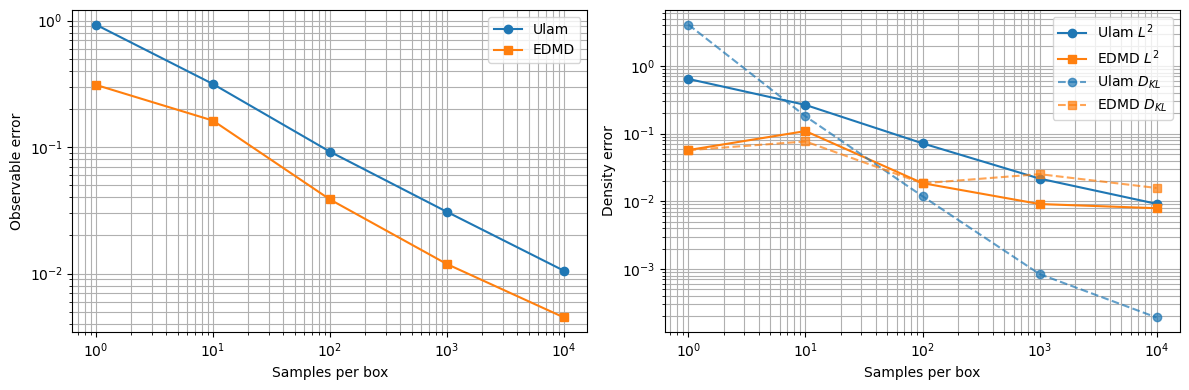

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))


# ==========================================================
# Left: Observable L2 error
# ==========================================================

ax[0].loglog(
    n_per_box_list,
    obs_l2_ulam,
    "o-",
    color="C0",
    label="Ulam"
)

ax[0].loglog(
    n_per_box_list,
    obs_l2_edmd,
    "s-",
    color="C1",
    label="EDMD"
)

ax[0].set_xlabel("Samples per box")
ax[0].set_ylabel(r"Observable error")
ax[0].grid(True, which="both")
ax[0].legend()



# ==========================================================
# Right: Density errors
# ==========================================================

# Ulam L2
ax[1].loglog(
    n_per_box_list,
    rho_l2_ulam,
    "o-",
    color="C0",
    label=r"Ulam $L^2$"
)

# EDMD L2
ax[1].loglog(
    n_per_box_list,
    rho_l2_edmd,
    "s-",
    color="C1",
    label=r"EDMD $L^2$"
)


# Ulam KL
ax[1].loglog(
    n_per_box_list,
    rho_KL_ulam,
    "o--",
    color="C0",
    alpha=0.7,
    label=r"Ulam $D_{KL}$"
)

# EDMD KL
ax[1].loglog(
    n_per_box_list,
    rho_KL_edmd,
    "s--",
    color="C1",
    alpha=0.7,
    label=r"EDMD $D_{KL}$"
)


ax[1].set_xlabel("Samples per box")
ax[1].set_ylabel("Density error")
ax[1].grid(True, which="both")
ax[1].legend()



plt.tight_layout()
plt.show()

# Impact of number of monomials

Simulating fast: 100%|██████████| 1000/1000 [00:01<00:00, 563.48it/s]



n_poly = 2
Saved to c:\Users\wagne\OneDrive\Dokumente\Universität\Master_Elektrotechnik\3.Semester\Forschungspraktikum\Code\K_PF_time_homogeneous_Markovian_RDS\Notebooks\Monomials.png
Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 100000/100000 [00:01<00:00, 55393.25it/s]


G condition number: 10.298239553893806
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
6.831948408117795e-16
Computing eigenvalues, eigenvectors and eigenfunctions...


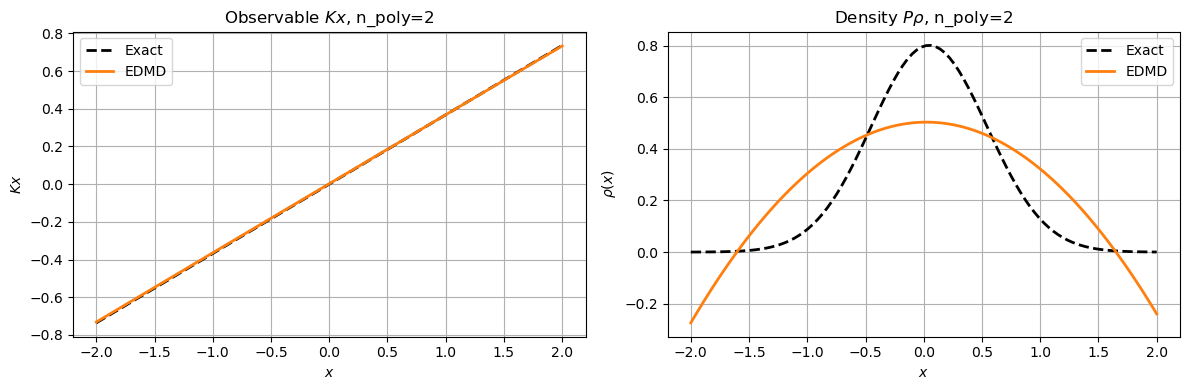


n_poly = 4
Saved to c:\Users\wagne\OneDrive\Dokumente\Universität\Master_Elektrotechnik\3.Semester\Forschungspraktikum\Code\K_PF_time_homogeneous_Markovian_RDS\Notebooks\Monomials.png
Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 100000/100000 [00:02<00:00, 41715.86it/s]


G condition number: 363.83800213193854
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
4.861166461101612e-14
Computing eigenvalues, eigenvectors and eigenfunctions...


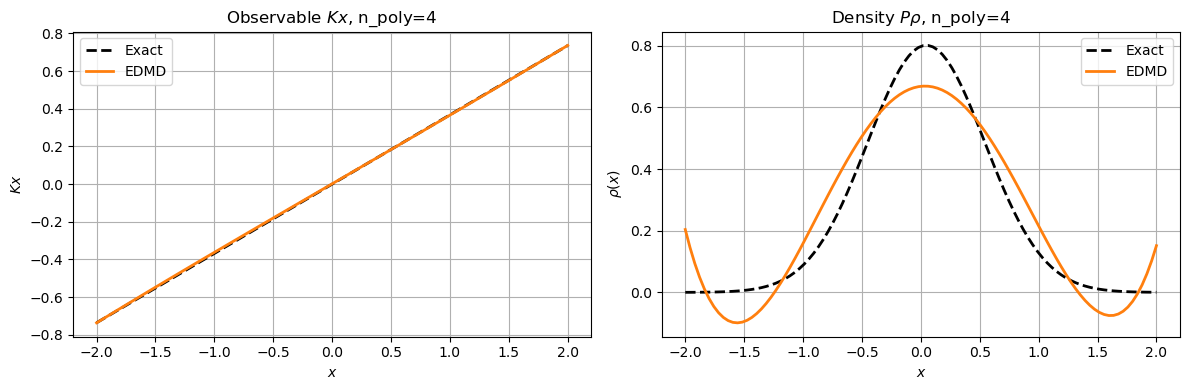


n_poly = 6
Saved to c:\Users\wagne\OneDrive\Dokumente\Universität\Master_Elektrotechnik\3.Semester\Forschungspraktikum\Code\K_PF_time_homogeneous_Markovian_RDS\Notebooks\Monomials.png
Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 100000/100000 [00:02<00:00, 33585.26it/s]


G condition number: 22664.180038013874
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
9.145737533835395e-12
Computing eigenvalues, eigenvectors and eigenfunctions...


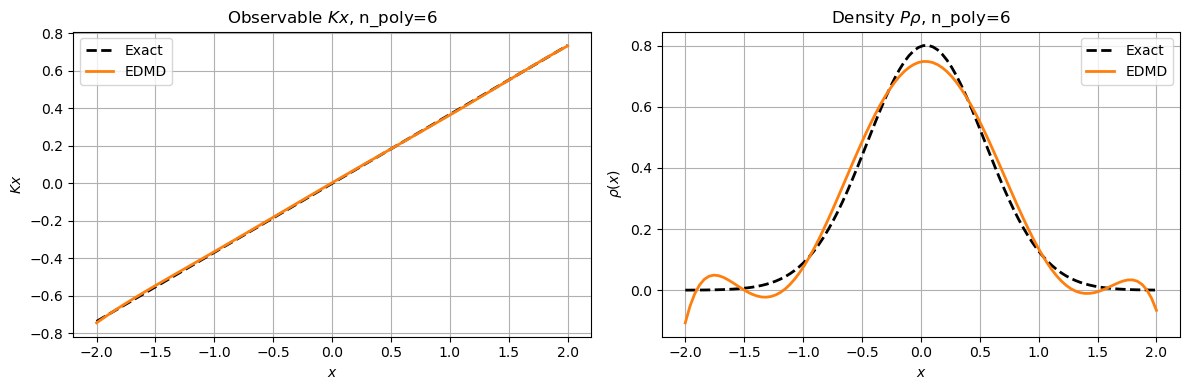


n_poly = 8
Saved to c:\Users\wagne\OneDrive\Dokumente\Universität\Master_Elektrotechnik\3.Semester\Forschungspraktikum\Code\K_PF_time_homogeneous_Markovian_RDS\Notebooks\Monomials.png
Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 100000/100000 [00:03<00:00, 29707.36it/s]


G condition number: 1636023.6977454778
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
9.490717238626427e-09
Computing eigenvalues, eigenvectors and eigenfunctions...


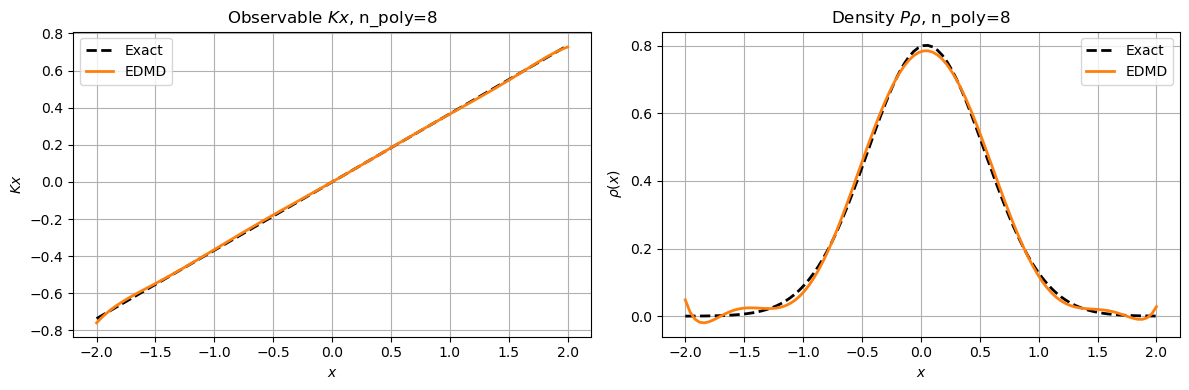


n_poly = 10
Saved to c:\Users\wagne\OneDrive\Dokumente\Universität\Master_Elektrotechnik\3.Semester\Forschungspraktikum\Code\K_PF_time_homogeneous_Markovian_RDS\Notebooks\Monomials.png
Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 100000/100000 [00:04<00:00, 24276.47it/s]


G condition number: 129667067.33063553
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
3.3242468865748083e-06
Computing eigenvalues, eigenvectors and eigenfunctions...


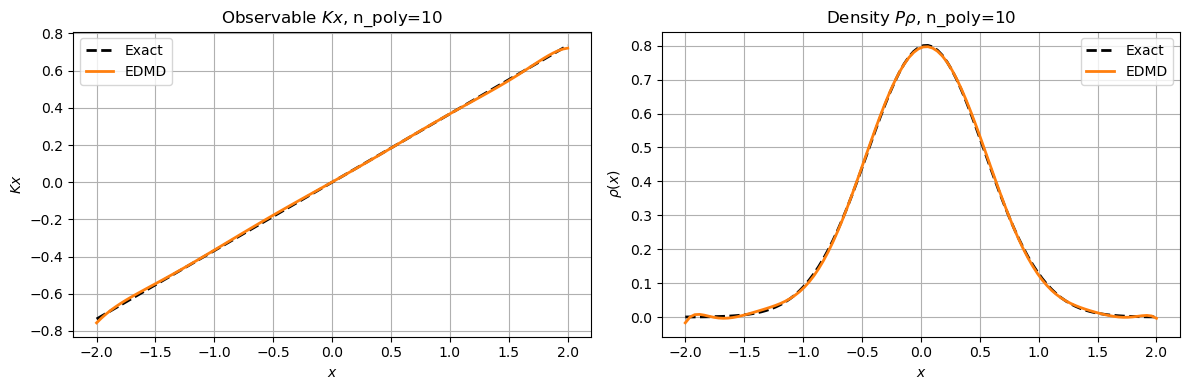


n_poly = 12
Saved to c:\Users\wagne\OneDrive\Dokumente\Universität\Master_Elektrotechnik\3.Semester\Forschungspraktikum\Code\K_PF_time_homogeneous_Markovian_RDS\Notebooks\Monomials.png
Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 100000/100000 [00:04<00:00, 21981.69it/s]


G condition number: 10832321102.11312
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
0.002931342535319731
Computing eigenvalues, eigenvectors and eigenfunctions...


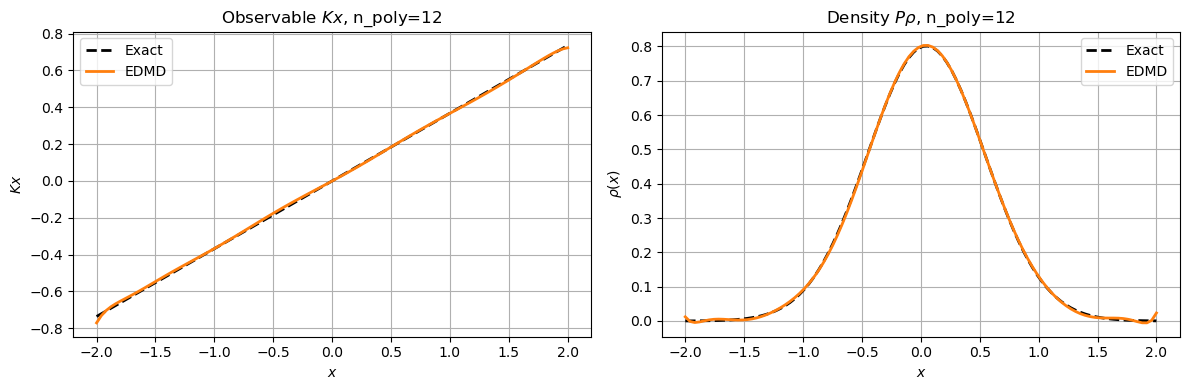


n_poly = 14
Saved to c:\Users\wagne\OneDrive\Dokumente\Universität\Master_Elektrotechnik\3.Semester\Forschungspraktikum\Code\K_PF_time_homogeneous_Markovian_RDS\Notebooks\Monomials.png
Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 100000/100000 [00:05<00:00, 18494.23it/s]


G condition number: 948034078593.386
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
11.339176732237615
Computing eigenvalues, eigenvectors and eigenfunctions...


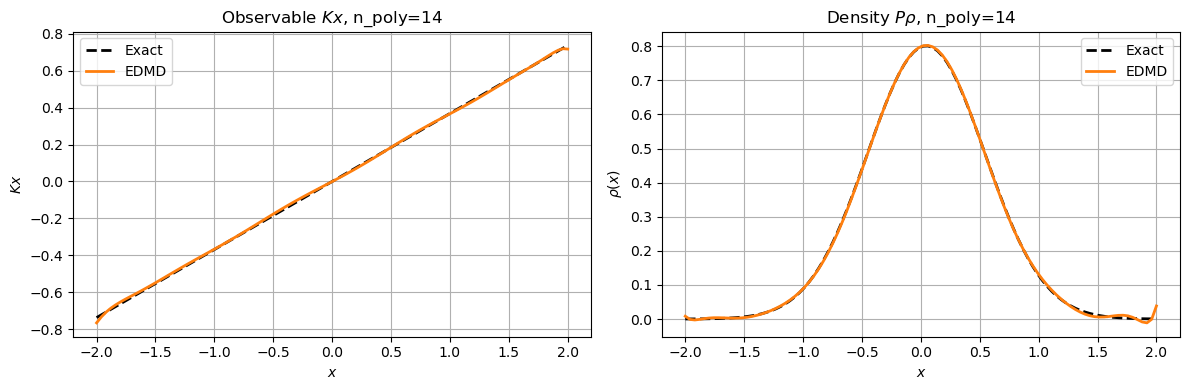


n_poly = 16
Saved to c:\Users\wagne\OneDrive\Dokumente\Universität\Master_Elektrotechnik\3.Semester\Forschungspraktikum\Code\K_PF_time_homogeneous_Markovian_RDS\Notebooks\Monomials.png
Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 100000/100000 [00:05<00:00, 17516.03it/s]


G condition number: 85220644701588.47
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
12265.150019367424
Computing eigenvalues, eigenvectors and eigenfunctions...


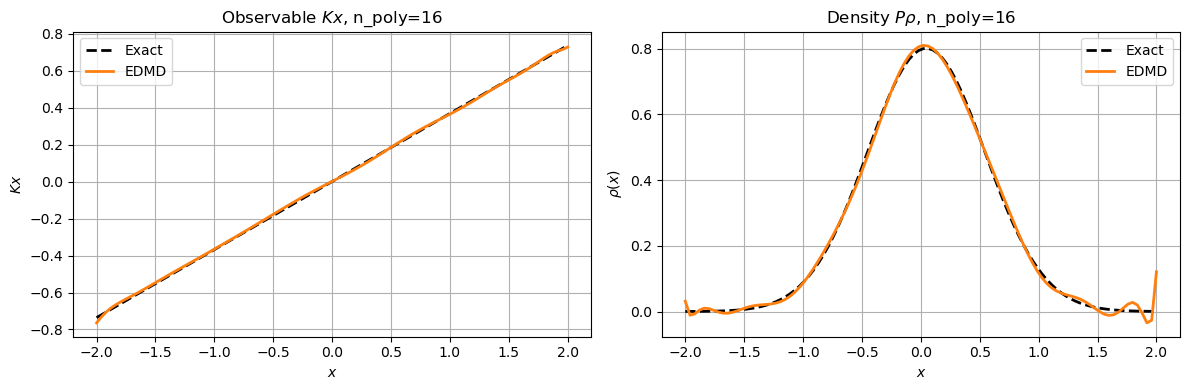

In [ ]:
# ==========================================================
# Parameters
# ==========================================================

n_poly_list = list(range(2, 18, 2))
n_per_box = 1000


# ==========================================================
# Error storage
# ==========================================================

# Observable
obs_linf_edmd = []
obs_l2_edmd = []

# Density
rho_linf_edmd = []
rho_l2_edmd = []
rho_KL_edmd = []



# ==========================================================
# Grid
# ==========================================================

x = np.linspace(xmin, xmax, Nx)
dx = x[1]-x[0]



# ==========================================================
# Generate data once
# ==========================================================

X = np.random.uniform(
    xmin,
    xmax,
    Nx*n_per_box
)

Y = OU.simulate_fast(
    x0=X,
    N=Nt,
    show_progress=True
)



# ==========================================================
# Observable
# ==========================================================

obs = x

obs_true = OU.eig_val(
    2,
    tau=1
) * x



# ==========================================================
# Density
# ==========================================================

rho = (
    OU.eig_func_POP(1,x)
    +
    0.25*OU.eig_func_POP(2,x)
)

rho = np.maximum(rho,0)

rho /= np.trapezoid(
    rho,
    x
)



rho_exact = (
    OU.eig_val(1,tau=1)
    *
    OU.eig_func_POP(1,x)
    +
    OU.eig_val(2,tau=1)
    *
    0.25
    *
    OU.eig_func_POP(2,x)
)

rho_exact = np.maximum(rho_exact,0)

rho_exact /= np.trapezoid(
    rho_exact,
    x
)



# ==========================================================
# KL divergence
# ==========================================================

def KL_divergence(p,q,x):

    eps = 1e-14

    p = np.maximum(p,eps)
    q = np.maximum(q,eps)

    return np.trapezoid(
        p*np.log(p/q),
        x
    )



# ==========================================================
# Loop over polynomial dictionary size
# ==========================================================

for n_poly in n_poly_list:

    print("\n============================")
    print("n_poly =", n_poly)
    print("============================")


    # ----------------------------------
    # EDMD
    # ----------------------------------

    M = sys.modules["function_dictionary"].Monomials(
        n_poly,
        TotalDegree=False,
        dim=1
    )


    edmd_M = sys.modules["edmd"].EDMD()

    edmd_M.setup(
        X,
        Y,
        M
    )



    # ======================================================
    # Observable
    # ======================================================

    obs_edmd = edmd_M.apply_K(
        obs,
        x
    )


    obs_linf_edmd.append(
        np.max(
            np.abs(obs_edmd-obs_true)
        )
    )


    obs_l2_edmd.append(
        np.sqrt(
            dx*np.sum(
                (obs_edmd-obs_true)**2
            )
        )
    )



    # ======================================================
    # Density
    # ======================================================

    rho_edmd = edmd_M.apply_P(
        rho,
        x
    )

    rho_edmd /= np.trapezoid(
        rho_edmd,
        x
    )



    rho_linf_edmd.append(
        np.max(
            np.abs(rho_edmd-rho_exact)
        )
    )


    rho_l2_edmd.append(
        np.sqrt(
            dx*np.sum(
                (rho_edmd-rho_exact)**2
            )
        )
    )


    rho_KL_edmd.append(
        KL_divergence(
            rho_exact,
            rho_edmd,
            x
        )
    )



    # ======================================================
    # Plot approximation
    # ======================================================

    fig, ax = plt.subplots(
        1,
        2,
        figsize=(12,4)
    )


    # Observable

    ax[0].plot(
        x,
        obs_true,
        "k--",
        lw=2,
        label="Exact"
    )

    ax[0].plot(
        x,
        obs_edmd,
        color="C1",
        lw=2,
        label="EDMD"
    )

    ax[0].set_title(
        f"Observable $Kx$, n_poly={n_poly}"
    )

    ax[0].set_xlabel("$x$")
    ax[0].set_ylabel("$Kx$")
    ax[0].grid(True)
    ax[0].legend()



    # Density

    ax[1].plot(
        x,
        rho_exact,
        "k--",
        lw=2,
        label="Exact"
    )

    ax[1].plot(
        x,
        rho_edmd,
        color="C1",
        lw=2,
        label="EDMD"
    )

    ax[1].set_title(
        f"Density $P\\rho$, n_poly={n_poly}"
    )

    ax[1].set_xlabel("$x$")
    ax[1].set_ylabel("$\\rho(x)$")
    ax[1].grid(True)
    ax[1].legend()


    plt.tight_layout()
    plt.show()



# ==========================================================
# Arrays
# ==========================================================

n_poly_list = np.asarray(n_poly_list)

obs_linf_edmd = np.asarray(obs_linf_edmd)
obs_l2_edmd = np.asarray(obs_l2_edmd)

rho_linf_edmd = np.asarray(rho_linf_edmd)
rho_l2_edmd = np.asarray(rho_l2_edmd)

rho_KL_edmd = np.asarray(rho_KL_edmd)

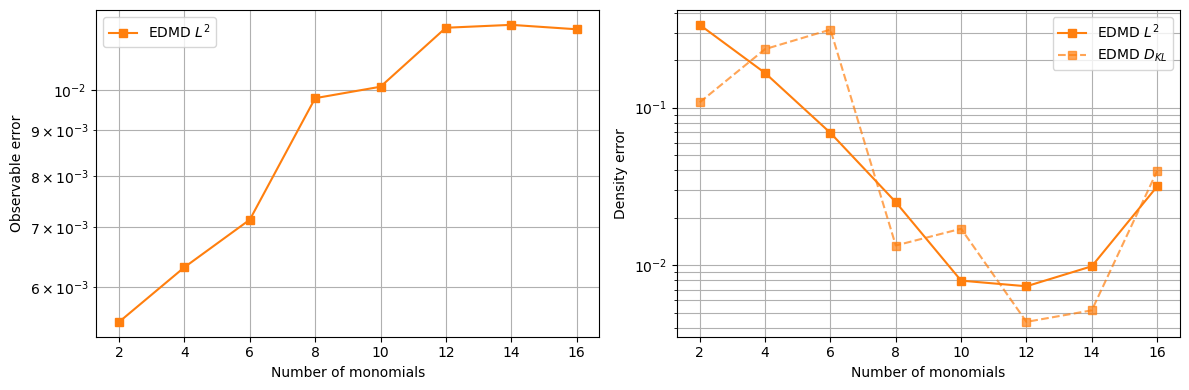

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))


# ==========================================================
# Left: Observable L2 error
# ==========================================================


ax[0].semilogy(
    n_poly_list,
    obs_l2_edmd,
    "s-",
    color="C1",
    label="EDMD $L^2$"
)

ax[0].set_xlabel("Number of monomials")
ax[0].set_ylabel(r"Observable error")
ax[0].grid(True, which="both")
ax[0].legend()



# ==========================================================
# Right: Density errors
# ==========================================================


# EDMD L2
ax[1].semilogy(
    n_poly_list,
    rho_l2_edmd,
    "s-",
    color="C1",
    label=r"EDMD $L^2$"
)


# EDMD KL
ax[1].semilogy(
    n_poly_list,
    rho_KL_edmd,
    "s--",
    color="C1",
    alpha=0.7,
    label=r"EDMD $D_{KL}$"
)


ax[1].set_xlabel("Number of monomials")
ax[1].set_ylabel("Density error")
ax[1].grid(True, which="both")
ax[1].legend()



plt.tight_layout()
plt.show()